# Marketplace Dynamics and Behavioral Patterns in Brazilian E-Commerce
*Exploring relationships across pricing, logistics, purchasing patterns, and customer activity.*

## 1. Introduction

This notebook continues directly from *Data Preparation and Merging*, using the cleaned and enriched `order_details` created during that stage.

The original Olist data consisted of nine interconnected relational datasets spanning customers, sellers, products, payments, reviews, geolocation records, order items, order information, and product category translations. These datasets existed across multiple granularities and required careful integration to create a unified analytical view. Preparing the data involved establishing relationships across operational, geographic, and transactional sources while preserving the structure needed for later analysis.

The resulting dataset enters this analysis at the order-item level. It has been cleaned, validated, and enriched with engineered features related to pricing, logistics, seller characteristics, and marketplace activity.

This exploratory analysis follows questions that emerged throughout preparation and early investigation. Rather than approaching the data with a predefined question, the analysis follows the structure of the marketplace itself. The Olist platform connects pricing, logistics, seller behavior, and customer experience in ways that are difficult to untangle cleanly. Patterns in one area have a way of pointing toward questions in another. The analysis begins broadly and narrows gradually, letting the data surface what matters.

## 2. Environment Setup

This section initializes the notebook environment, including the libraries, display settings, and visualization conventions used to maintain consistency throughout the analysis.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
# File handling
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

# Data manipulation and utilities
import pandas as pd
import numpy as np

# Visualization
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import geopandas as gpd
from shapely.geometry import Point

# Statistical analysis
from statsmodels.stats.multitest import multipletests

# Custom modules
from src.config.paths import PROCESSED_DATA
from src.config.colors import (
    SKY, TEAL, CORAL, YELLOW, CYAN, LABEL,
    PALETTE_ON_TIME, CUSTOMER_DENSITY_SCALE, SELLER_DENSITY_SCALE,
)
from src.config.plotly.charts_template import custom_dark
from src.io.data_loader import load_geo
from src.io.sidrapi import load_population_table
from src.stats.summary_stats import get_num_observations, get_num_features, get_purchase_window
from src.stats.geo_stats import compute_concentration
from src.stats.aggregation import binned_aggregate, monthly_aggregate
from src.stats.comparisons import (
    compare_two_groups,
    compare_groups_kruskal,
    chi_square_test,
    spearman_summary,
    format_test_result,
)
from src.maps.brazil_map import BrazilMap
from src.maps.bivariate_map import BivariateBrazilMap, bivariate_index
from src.utils.geometry import bezier_arc
from src.utils.misc_helpers import clean_population
from src.utils.table_template import display_stylized_table
from src.reporting.tables import display_dataset_at_a_glance
from src.charts.cumulative_combo_chart import build_cumulative_combo_chart
from src.charts.time_series_chart import build_time_series_chart
from src.nlp.text_pt import distinctive_words

# Warnings
import warnings

In [3]:
# DataFrame display
pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 120)

# Suppress non-critical warnings for cleaner notebook output
warnings.filterwarnings("ignore")

# Every hypothesis test registers its result to help correct for multiplicity
tests = {}

## 3. Unified Marketplace Overview
The analysis begins by loading the cleaned and enriched `order_details` dataset created during the data preparation stage.

In [4]:
all_orders = pd.read_parquet(PROCESSED_DATA / "order_details.parquet")

In [5]:
# Get summary stats
n_observations = get_num_observations(all_orders)
n_features = get_num_features(all_orders)
purchase_start, purchase_end = get_purchase_window(all_orders)

# Format for presentation
n_observations_display = f"{n_observations:,}"
purchase_window_display = (
    f"{purchase_start:%b %Y}"
    f" to "
    f"{purchase_end:%b %Y}"
)

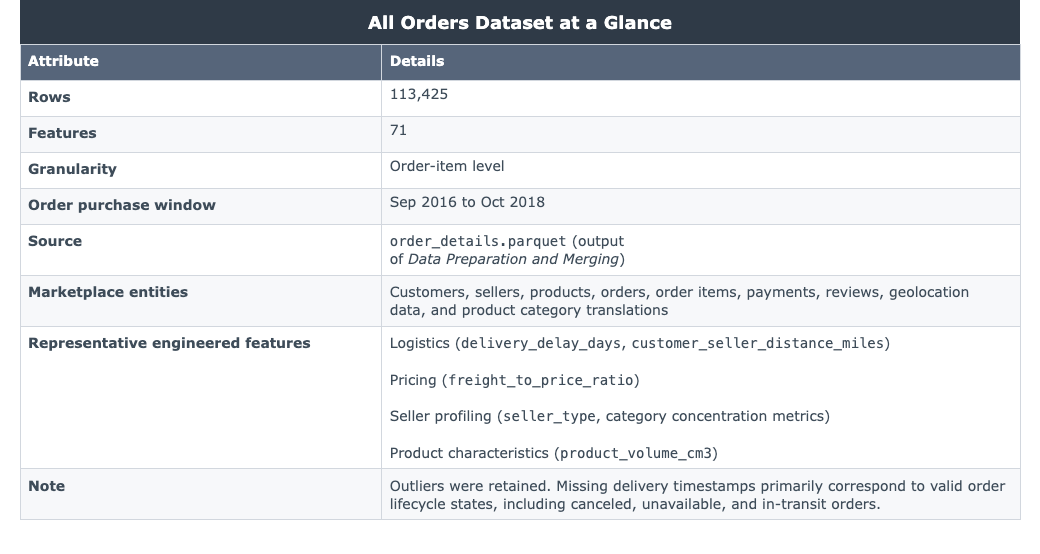

In [6]:
display_dataset_at_a_glance(
    n_observations=n_observations_display,
    n_features=n_features,
    purchase_window=purchase_window_display
)

The preparation notebook identified extreme values in fields such as price, freight, product weight and delivery time, and kept them. This analysis keeps them too. It summarizes with medians and uses rank-based tests, which are not sensitive to extreme values, and it trims long tails only in charts, for legibility.

## 4. Marketplace Geography

An order placed on Olist might connect a customer with a seller in the same city or one halfway across the country. How often each happens depends on where Olist’s sellers are based and where their customers live. This section maps both, then measures the distances between them, which sets up the delivery times and freight charges examined in Section 5.

Throughout this section, distance refers to the estimated geographic separation between seller and customer, calculated from approximate location coordinates. Actual shipping routes may be longer or less direct.

In [7]:
# Filter for orders with associated item records
orders_with_items = all_orders[all_orders["has_items"]]

# Get unique customer and seller locations for mapping
customer_locations = orders_with_items.drop_duplicates(subset="customer_unique_id")
seller_locations = orders_with_items.drop_duplicates(subset="seller_id")

# Customer coordinates
customer_lat = customer_locations["customer_lat"]
customer_lng = customer_locations["customer_lng"]

# Seller coordinates
seller_lat = seller_locations["seller_lat"]
seller_lng = seller_locations["seller_lng"]

In [8]:
# Load geographic data for mapping from IBGE API
states_2018 = load_geo("states", year=2018)
brazil_outline_2018 = load_geo("country", year=2018)
municipalities_2018 = load_geo("municipalities", year=2018)

### 4.1 Where are customers and sellers concentrated?

The geographic distribution of customers and sellers provides context for understanding Olist’s marketplace reach. Each distinct customer and seller is represented once using their first observed location in the included data. Areas of higher density therefore indicate concentrations of customers and sellers, providing context for later analyses of distance, freight costs, and delivery performance.

In [9]:
# Compute density/concentration for customers and sellers
customer_density = compute_concentration(customer_lat, customer_lng)
seller_density = compute_concentration(seller_lat, seller_lng)

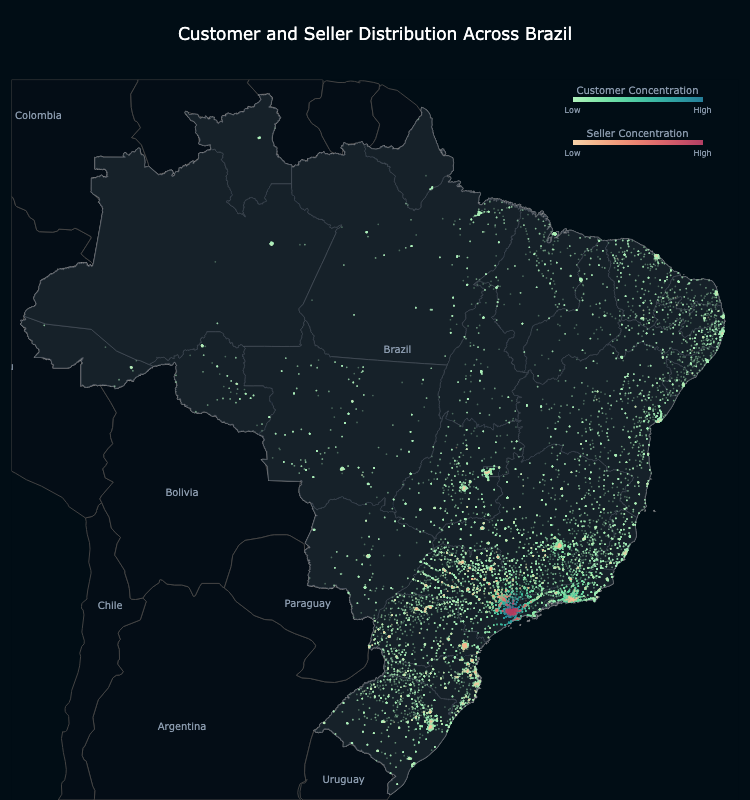

In [10]:
marketplace_activity_map = (BrazilMap(
    brazil_outline=brazil_outline_2018, 
    title=dict(text="Customer and Seller Distribution Across Brazil"), 
    margin=dict(t=80))
        .add_brazil_states(states_2018)
        .add_density_layer(
            customer_lat, 
            customer_lng, 
            customer_density, 
            CUSTOMER_DENSITY_SCALE, 
            "Customer Concentration", 
            colorbar_x=0.85, 
            colorbar_y=0.94, 
            length=0.2
        )
        .add_density_layer(
            seller_lat, 
            seller_lng, 
            seller_density, 
            SELLER_DENSITY_SCALE, 
            "Seller Concentration", 
            colorbar_x=0.85, 
            colorbar_y=0.88, 
            length=0.2
        )
        .show())

Customers and sellers are concentrated in southeastern Brazil, particularly around São Paulo. Sellers appear more tightly clustered, while customers extend more broadly across the South, Northeast, and other regions of the country.

### 4.2 Why are customers concentrated in the Southeast?

Population distribution may help explain the concentration of customers in the Southeast. Comparing distinct customers per 1,000 residents with population density across municipalities shows how Olist’s customer presence varies relative to the local population. Population estimates are averaged across 2016–2018, corresponding to the period covered by the order data.

In [11]:
pop_2016 = load_population_table(period="2016")
pop_2017 = load_population_table(period="2017")
pop_2018 = load_population_table(period="2018")

In [12]:
geometry = [Point(xy) for xy in zip(orders_with_items["customer_lng"], orders_with_items["customer_lat"])]
customer_geo = gpd.GeoDataFrame(orders_with_items, geometry=geometry, crs="EPSG:4326")
customer_geo = customer_geo.to_crs(municipalities_2018.crs)

In [13]:
# Match points to polygons by physical location
joined_data = gpd.sjoin(customer_geo, municipalities_2018, predicate="within", how="inner")

# Count unique customers within each municipality
city_counts = (
    joined_data.groupby("code_muni")["customer_unique_id"]
    .nunique()
    .reset_index(name="customer_count")
)

# Merge counts into cities GeoDataFrame
cities_with_counts = municipalities_2018.merge(city_counts, on="code_muni", how="left")
cities_with_counts["customer_count"] = cities_with_counts["customer_count"].fillna(0)

print(cities_with_counts[["name_muni", "customer_count"]].sort_values("customer_count", ascending=False).head(10))

                  name_muni  customer_count
3829              São Paulo         14866.0
3242         Rio de Janeiro          6588.0
2309         Belo Horizonte          2666.0
5571               Brasília          2059.0
4005               Curitiba          1456.0
3375               Campinas          1387.0
4933           Porto Alegre          1320.0
2162               Salvador          1203.0
3479              Guarulhos          1143.0
3811  São Bernardo do Campo           900.0


In [14]:
pop_2016 = clean_population(pop_2016, 2016)
pop_2017 = clean_population(pop_2017, 2017)
pop_2018 = clean_population(pop_2018, 2018)

In [15]:
# Merge all three populations on code_muni
pop_all = pop_2016.merge(pop_2017, on="code_muni").merge(pop_2018, on="code_muni")

# Compute average
pop_all["population_avg"] = pop_all[["population_2016", "population_2017", "population_2018"]].mean(axis=1).astype(int)

print(pop_all.head())

   code_muni  population_2016  population_2017  population_2018  population_avg
0    1100015            25506            25437            23167           24703
1    1100023           105896           107345           106168          106469
2    1100031             6289             6224             5438            5983
3    1100049            87877            88507            84813           87065
4    1100056            17959            17934            16444           17445


In [16]:
cities_with_counts = cities_with_counts.merge(pop_all[["code_muni", "population_avg"]], on="code_muni", how="left")

# Customers per 1000 residents
cities_with_counts["customers_per_1k"] = (cities_with_counts["customer_count"] / cities_with_counts["population_avg"]) * 1000

print(cities_with_counts[["name_muni", "customer_count", "population_avg", "customers_per_1k"]].sort_values("customers_per_1k", ascending=False).head(10))

                   name_muni  customer_count  population_avg  customers_per_1k
4416                   Ibiam             4.0          1964.0          2.036660
3483                Holambra            28.0         14096.0          1.986379
2277  Antônio Prado de Minas             3.0          1647.0          1.821494
3812      São Caetano do Sul           270.0        159569.0          1.692058
3222                 Niterói           806.0        502899.0          1.602708
3809                  Santos           686.0        434019.0          1.580576
3817     São João de Iracema             3.0          1903.0          1.576458
3331                 Barueri           416.0        267925.0          1.552673
4508                Piratuba             6.0          4092.0          1.466276
4585            Treze Tílias            11.0          7541.0          1.458692


In [17]:
# Compute area in squared miles from geometry
municipalities_2018["area_km2"] = municipalities_2018.to_crs("EPSG:5880").area / 1_000_000
municipalities_2018["area_mi2"] = municipalities_2018["area_km2"] * 0.386102

# Merge area into cities_with_counts
cities_with_counts = cities_with_counts.merge(
    municipalities_2018[["code_muni", "area_mi2"]],
    on="code_muni",
    how="left",
)

# Density per square mile
cities_with_counts["density_per_mi2"] = cities_with_counts["population_avg"] / cities_with_counts["area_mi2"]

# Bivariate class: population density (rows) × customers per 1k (columns).
# Cities with zero customers are left unclassified.
cities_with_counts["bivar_idx"] = bivariate_index(
    x=cities_with_counts["customers_per_1k"].replace(0, np.nan),
    y=cities_with_counts["density_per_mi2"],
)

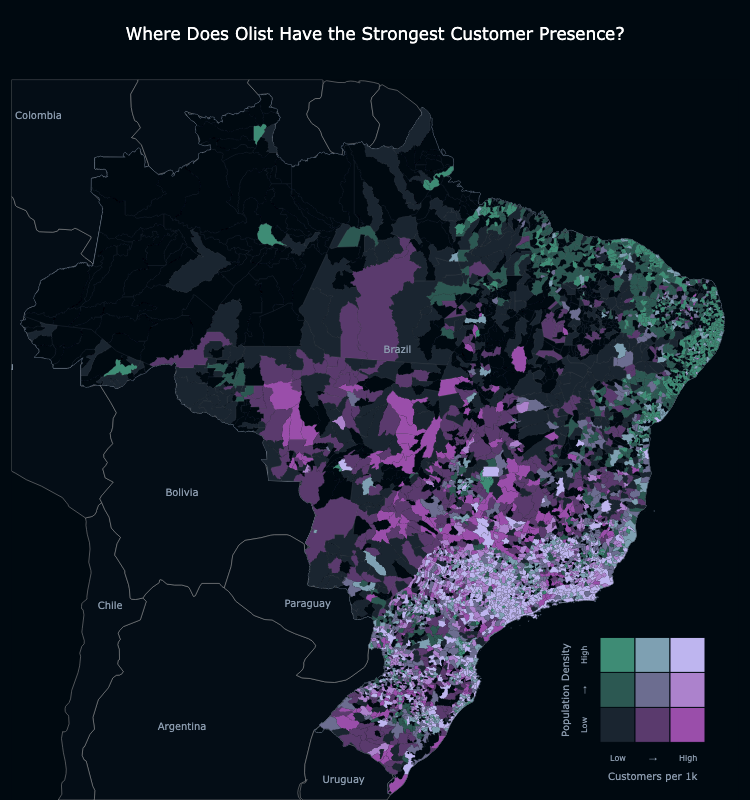

In [18]:
bivariate_map = (BivariateBrazilMap(
    brazil_outline=brazil_outline_2018,
    title=dict(text="Where Does Olist Have the Strongest Customer Presence?"),
    margin=dict(t=80))
        .add_brazil_municipalities(cities_with_counts)
        .add_bivariate_layer(cities_with_counts)
        .add_bivariate_legend(x_title="Customers per 1k", y_title="Population Density")
        .show())

Olist’s customer presence is strongest across much of the South and Southeast, while many densely populated municipalities in the Northeast have relatively few customers per 1,000 residents. Some municipalities in central Brazil show the opposite pattern: low population density but relatively high customer presence per resident. With sellers concentrated in the Southeast and customers spread more broadly, estimated seller–customer distances help characterize the geographic scale of these connections.

### 4.3 How far apart are customers and sellers?

Olist’s sellers cluster around São Paulo, while its customers are spread more widely across Brazil, so the distance between them varies from order to order. The distribution below shows the estimated distance between seller and customer for each order item.

0.5    269.0
0.9    901.0
Name: customer_seller_distance_miles, dtype: float64


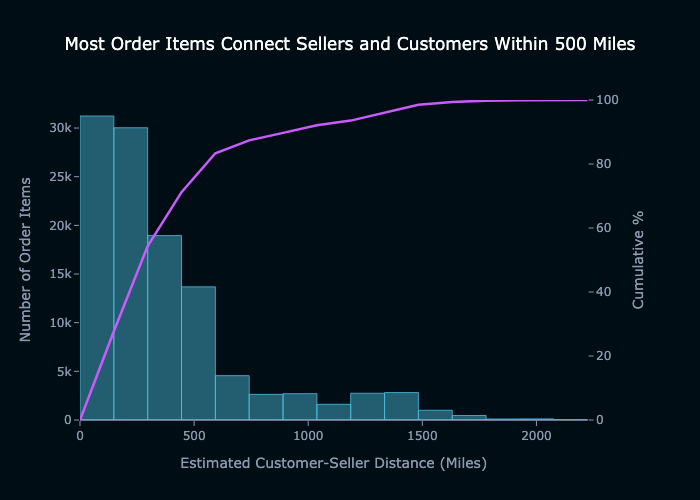

In [19]:
fig_dist = build_cumulative_combo_chart(
    series=orders_with_items["customer_seller_distance_miles"],
    bins=15,
    title="Most Order Items Connect Sellers and Customers Within 500 Miles",
    x_label="Estimated Customer-Seller Distance (Miles)",
    y_left_label="Number of Order Items",
    bar_name="Order items",
)

print(orders_with_items["customer_seller_distance_miles"].quantile([0.5, 0.9]).round(0))

fig_dist.show(renderer="png")

Half of order items connect a seller and customer within about 270 miles, and 90% within about 900 miles. The remaining tenth spans much longer distances, up to roughly 2,000 miles, which reflects customers far from the Southeast buying from sellers concentrated there.

In [20]:
# Sample for legibility
sample = (
    orders_with_items
    .dropna(subset=[
        "customer_lat", "customer_lng",
        "seller_lat", "seller_lng",
        "customer_seller_distance_miles",
    ])
    .sample(n=3000, random_state=42)
)

The map below shows a random sample of 3,000 order items. Each arc connects the estimated locations of a seller and customer. Actual shipping routes may differ.

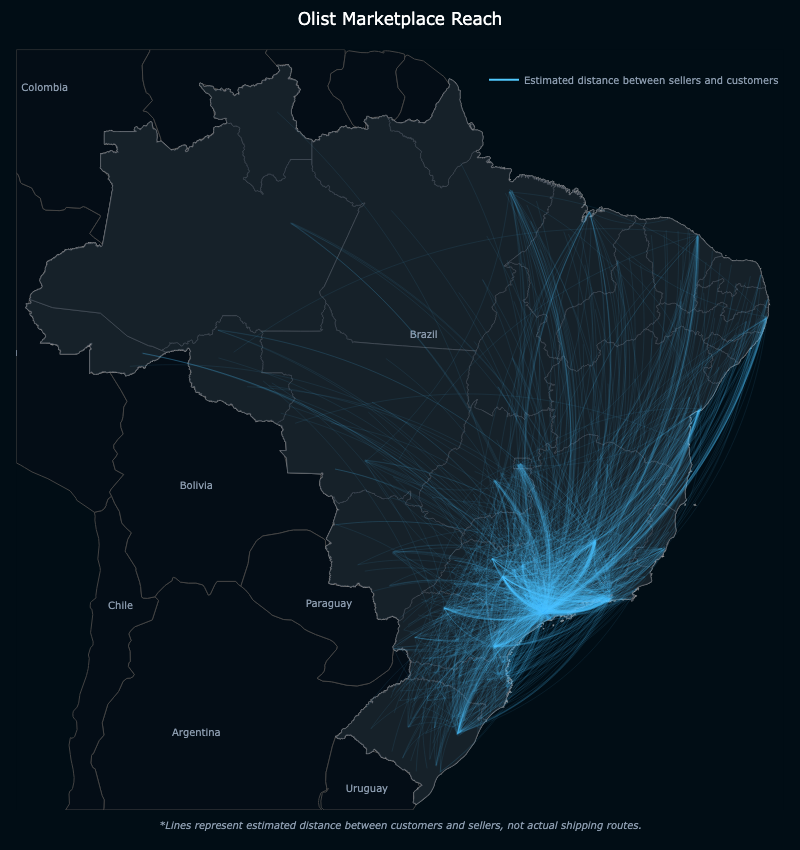

In [21]:
bm = BrazilMap(
    brazil_outline_2018, 
    width=800, 
    height=850, 
    margin=dict(l=0, r=0, t=50, b=40),
    title=dict(text="Olist Marketplace Reach", x=0.5)
).add_brazil_states(states_2018)

for _, r in sample.iterrows():
    la, lo = bezier_arc(
        r.seller_lat, 
        r.seller_lng, 
        r.customer_lat, 
        r.customer_lng
    )
    bm.add_scatter(
        la, 
        lo, 
        mode="lines", 
        line=dict(color=CYAN, width=0.3), 
        opacity=0.3
    )

bm.figure.add_trace(go.Scattergeo(
    lat=[None], 
    lon=[None], 
    mode="lines",
    line=dict(color=CYAN, width=2),
    name="Estimated distance between sellers and customers", 
    showlegend=True,
))

bm.figure.add_annotation(
    text="<i>*Lines represent estimated distance between customers and sellers, not actual shipping routes.</i>",
    xref="paper", 
    yref="paper", 
    x=0.5, 
    y=-0.03, 
    xanchor="center",
    showarrow=False, 
    font=dict(color=LABEL, size=10),
)

bm.figure.update_layout(
    showlegend=True, 
    legend=dict(
        x=0.98, 
        y=0.98, 
        xanchor="right", 
        yanchor="top",
        bgcolor="rgba(0,0,0,0)", 
        font=dict(color=LABEL, size=10)
    )
)
bm.show()

The sampled connections are densest in southeastern Brazil, with longer links extending into the Northeast, North, and Central-West.

## 5. Delivery Performance: Distance, Delays, and Cost

Section 4 described where customers and sellers are concentrated and the estimated distances connecting them within orders. This section looks at how long deliveries take, how they compare with estimated delivery dates, and how delivery time, lateness, and freight charges vary with distance.

### 5.1 How long do deliveries take?

Before relating delivery time to distance, it helps to see how long orders take to arrive. Delivery duration is measured in whole days from purchase to delivery to the customer, with partial days rounded down. It is available only for delivered orders, and each order is counted once.

Delivered orders: 96,476
Median: 10 days | middle half: 6 to 15 days | 95th percentile: 29 days


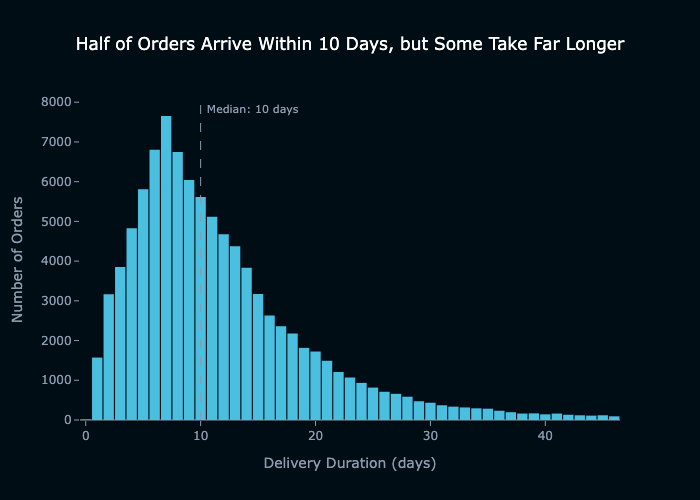

In [22]:
# One observation per order; only delivered orders have a duration
orders_unique = orders_with_items.drop_duplicates(subset="order_id")
duration_days_full = orders_unique["delivery_duration_days"].dropna()

q25, median_days, q75, p95 = duration_days_full.quantile([0.25, 0.5, 0.75, 0.95])
print(f"Delivered orders: {len(duration_days_full):,}")
print(f"Median: {median_days:.0f} days | middle half: {q25:.0f} to {q75:.0f} days | 95th percentile: {p95:.0f} days")

# Limit range for visibility in the chart
duration_days = duration_days_full[duration_days_full <= duration_days_full.quantile(0.99)]

fig = go.Figure(go.Histogram(
    x=duration_days, 
    xbins=dict(start=-0.5, size=1), 
    marker=dict(color=SKY)
    )
)
fig.add_vline(x=median_days, line=dict(color=LABEL, width=1, dash="dash"))
fig.add_annotation(
    x=median_days, 
    y=1, 
    yref="paper", 
    xanchor="left", 
    showarrow=False,
    text=f" Median: {median_days:.0f} days", 
    font=dict(color=LABEL, size=11),
)
fig.update_layout(
    template=custom_dark, 
    title="Half of Orders Arrive Within 10 Days, but Some Take Far Longer", 
    showlegend=False, 
    bargap=0.1
)
fig.update_xaxes(title_text="Delivery Duration (days)", showgrid=False)
fig.update_yaxes(title_text="Number of Orders", showgrid=False)
fig.show(renderer="png")

Delivered orders take a median of 10 days to arrive, and half arrive within 6 to 15 days. The distribution has a long right tail: 5% of orders take 29 days or more. The slowest 1% of orders are omitted from the chart for legibility.

### 5.2 How does delivery time vary with distance?

Greater geographic separation between sellers and customers may translate into longer waits. Comparing median delivery duration across estimated distance ranges shows how delivery times vary, while counts of orders indicate how many observations support each median.

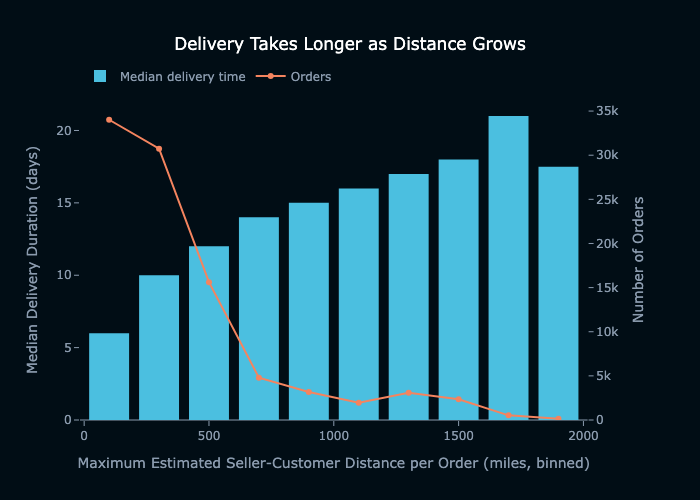

In [23]:
BIN_WIDTH = 200
MIN_BIN_N = 100

# One row per order: farthest seller distance and delivery duration
order_delivery = (
    orders_with_items.groupby("order_id", as_index=False)
    .agg(
        distance=("customer_seller_distance_miles", "max"),
        delivery_duration_days=("delivery_duration_days", "first"),
        purchased=("order_purchase_timestamp", "first"),
        handed_to_carrier=("order_delivered_carrier_date", "first"),
        delivered=("order_delivered_customer_date", "first"),
    )
)

# Use the same observations for medians and counts
delivery_data = order_delivery.dropna(subset=["distance", "delivery_duration_days"])

duration_by_distance = binned_aggregate(
    delivery_data, 
    "distance", 
    "delivery_duration_days", 
    min_n=MIN_BIN_N
)

fig = make_subplots(specs=[[{"secondary_y": True}]])
fig.add_trace(
    go.Bar(
        x=duration_by_distance["bin_mid"], 
        y=duration_by_distance["value"],
        marker=dict(color=SKY), 
        name="Median delivery time"
    ),
    secondary_y=False,
)
fig.add_trace(
    go.Scatter(
        x=duration_by_distance["bin_mid"], 
        y=duration_by_distance["n"],
        mode="lines+markers", 
        line=dict(color=CORAL, width=2), 
        name="Orders"
    ),
    secondary_y=True,
)
fig.update_layout(
    template=custom_dark, 
    title="Delivery Takes Longer as Distance Grows", 
    showlegend=True, 
    legend=dict(orientation="h", y=1.12, x=0)
)
fig.update_xaxes(
    title_text="Maximum Estimated Seller-Customer Distance per Order (miles, binned)"
)
fig.update_yaxes(
    title_text="Median Delivery Duration (days)", 
    secondary_y=False, 
    showgrid=False
)
fig.update_yaxes(
    title_text="Number of Orders", 
    secondary_y=True, 
    showgrid=False, 
    rangemode="tozero", 
    zeroline=False
)
fig.show(renderer="png")

In [24]:
tests["5.2 Distance vs. duration"] = spearman_summary(
    delivery_data["distance"],
    delivery_data["delivery_duration_days"],
    "Distance vs. delivery duration",
)

print(format_test_result(tests["5.2 Distance vs. duration"]))

Distance vs. delivery duration: a statistically significant correlation (Spearman rho = 0.54, n=96,476, p < 0.001, large)


Estimated seller–customer distance is positively associated with delivery duration (Spearman’s ρ = 0.54). This aligns with the rising median delivery times across distance ranges, although distance alone does not account for all variation in delivery time.

Delivery time has two stages: the time before an order is handed to the carrier, and the carrier’s transit to the customer. Splitting the wait into these stages shows which one accounts for longer deliveries at greater distances.

Orders with usable stage timestamps: 96,287 of 96,475
Median handling: 2.2 days | median transit: 7.1 days
bin_mid  value     n
  100.0    3.7 33975
  300.0    7.2 30669
  500.0    9.1 15580
  700.0   11.1  4779
  900.0   12.9  3158
 1100.0   13.9  1962
 1300.0   14.2  3089
 1500.0   14.8  2347
 1700.0   17.3   522
 1900.0   15.0   149


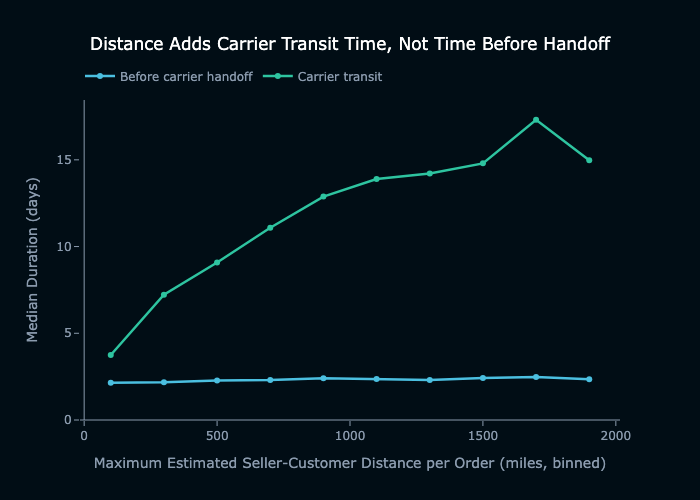

In [25]:
# The prepared data includes whole-day versions of these stages (shipping_delay_days and
# carrier_delivery_days). They are recomputed here in fractional days, because time before
# handoff is typically about two days and whole-day rounding would hide differences of that size.
ONE_DAY = pd.Timedelta(days=1)

stages = order_delivery.dropna(subset=["distance", "purchased", "handed_to_carrier", "delivered"]).assign(
    handling_days=lambda d: (d["handed_to_carrier"] - d["purchased"]) / ONE_DAY,
    transit_days=lambda d: (d["delivered"] - d["handed_to_carrier"]) / ONE_DAY,
)

# A small number of records have timestamps out of order; exclude them
valid_stages = stages[(stages["handling_days"] >= 0) & (stages["transit_days"] >= 0)]

print(f"Orders with usable stage timestamps: {len(valid_stages):,} of {len(stages):,}")
print(f"Median handling: {valid_stages['handling_days'].median():.1f} days | median transit: {valid_stages['transit_days'].median():.1f} days")

handling_by_distance = binned_aggregate(valid_stages, "distance", "handling_days", min_n=MIN_BIN_N)
transit_by_distance = binned_aggregate(valid_stages, "distance", "transit_days", min_n=MIN_BIN_N)
print(transit_by_distance[["bin_mid", "value", "n"]].round(1).to_string(index=False))

fig = go.Figure()
fig.add_trace(go.Scatter(
    x=handling_by_distance["bin_mid"], 
    y=handling_by_distance["value"],
    mode="lines+markers", 
    line=dict(color=SKY, width=2.5), 
    name="Before carrier handoff",
))
fig.add_trace(go.Scatter(
    x=transit_by_distance["bin_mid"], 
    y=transit_by_distance["value"],
    mode="lines+markers", 
    line=dict(color=TEAL, width=2.5), 
    name="Carrier transit",
))
fig.update_layout(
    template=custom_dark, 
    title="Distance Adds Carrier Transit Time, Not Time Before Handoff", 
    showlegend=True, 
    legend=dict(orientation="h", y=1.12, x=0)
)
fig.update_xaxes(
    title_text="Maximum Estimated Seller-Customer Distance per Order (miles, binned)", 
    showgrid=False
)
fig.update_yaxes(
    title_text="Median Duration (days)", 
    rangemode="tozero", 
    showgrid=False
)
fig.show(renderer="png")

The median order spends 2.2 days before it is handed to the carrier and 7.1 days in transit. Time before handoff is nearly constant across distances, at a little over 2 days. Median transit time rises from 3.7 days for orders within 200 miles to about 14 to 15 days between 1,000 and 1,600 miles, and peaks at 17.3 days at 1,600–1,800 miles. The longer waits at greater distances therefore come from the carrier stage. 188 orders (0.2%) with out-of-sequence timestamps are excluded.

### 5.3 How common are late orders?

Orders are considered late when they arrive after their estimated delivery date. This analysis examines the share of delivered orders that arrive late and how far actual delivery falls from the estimate, counting each order once.

In [26]:
delay_days_full = orders_unique["delivery_delay_days"].dropna()
pct_on_time = delay_days_full.le(0).mean() * 100
median_delay = delay_days_full.median()

# How far actual delivery falls from the estimate, in either direction
estimate_gap = delay_days_full.abs()


print(f"On or before estimate: {pct_on_time:.1f}%")
print(f"Median arrival: {-median_delay:.0f} days before the estimate")
print(f"Typical gap from the estimate: median {estimate_gap.median():.0f} days, mean {estimate_gap.mean():.1f} days")
print(f"Delivered within 3 days of the estimate: {(estimate_gap <= 3).mean() * 100:.1f}%")

On or before estimate: 93.2%
Median arrival: 12 days before the estimate
Typical gap from the estimate: median 13 days, mean 13.3 days
Delivered within 3 days of the estimate: 8.2%


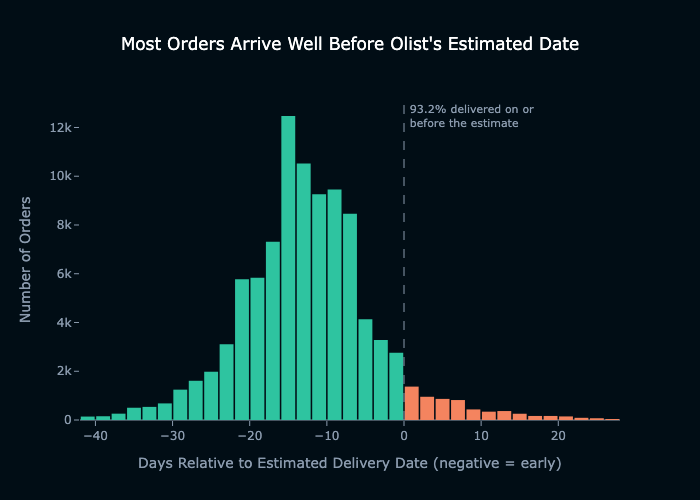

In [27]:
# Limit range for visibility in the chart
lower, upper = delay_days_full.quantile([0.005, 0.995])
delay_days = delay_days_full[delay_days_full.between(lower, upper)]

# Two-day bins rounded to outer edges so (-2, 0] is on-time, (0, 2] is late
start = 2 * np.floor(lower / 2)
stop = 2 * np.ceil(upper / 2)
edges = np.arange(start, stop + 2, 2)

delay_bins = pd.cut(delay_days, bins=edges, right=True, include_lowest=True)
bin_counts = delay_bins.value_counts(sort=False)

centers = np.array([interval.mid for interval in bin_counts.index])
bar_colors = [PALETTE_ON_TIME[interval.right <= 0] for interval in bin_counts.index]

fig = go.Figure(go.Bar(
    x=centers, 
    y=bin_counts.values, 
    width=1.8, 
    marker=dict(color=bar_colors)
))
fig.add_vline(x=0, line=dict(color=LABEL, width=1, dash="dash"))
fig.add_annotation(
    x=0, 
    y=1, 
    yref="paper", 
    xanchor="left", 
    showarrow=False, 
    align="left",
    text=f" {pct_on_time:.1f}% delivered on or<br> before the estimate",
    font=dict(color=LABEL, size=11),
)
fig.update_layout(
    template=custom_dark, 
    title="Most Orders Arrive Well Before Olist's Estimated Date", 
    showlegend=False
)
fig.update_xaxes(
    title_text="Days Relative to Estimated Delivery Date (negative = early)", 
    range=[edges[0], edges[-1]], 
    showgrid=False
)
fig.update_yaxes(title_text="Number of Orders", showgrid=False)
fig.show(renderer="png")

93.2% of orders arrive on or before the estimated delivery date, and the median order arrives 12 days early. With a buffer that large, an on-time delivery is not necessarily a fast one. The estimate is also rarely close: actual delivery falls a median of 13 days from the estimated date, and only 8.2% of orders arrive within 3 days of it. A gap this wide raises the question of how closely delivery time could be anticipated. The chart omits the most extreme 1% of orders, 0.5% at each end.

### 5.4 Are longer-distance orders more likely to arrive late?

Longer-distance orders generally take more time to arrive, but delivery estimates may already account for that additional time. Comparing late-delivery rates across estimated distance ranges shows whether longer-distance orders also miss their estimates more often.

In [28]:
# One row per order: farthest seller distance and on-time status
distance_late = (
    orders_with_items.groupby("order_id", as_index=False)
    .agg(
        distance=("customer_seller_distance_miles", "max"),
        delivered_on_time=("delivered_on_time", "first"),
    )
    .dropna(subset=["distance", "delivered_on_time"])
)

# Orders per 200-mile bin
bin_start = (distance_late["distance"] // BIN_WIDTH) * BIN_WIDTH
bin_sizes = bin_start.value_counts().sort_index()

# The last bin with enough orders becomes open-ended and absorbs the sparse tail
last_full_start = int(bin_sizes[bin_sizes >= MIN_BIN_N].index.max())
edges = [*range(0, last_full_start + 1, BIN_WIDTH), np.inf]

distance_late["distance_bin"] = pd.cut(distance_late["distance"], bins=edges, right=False)

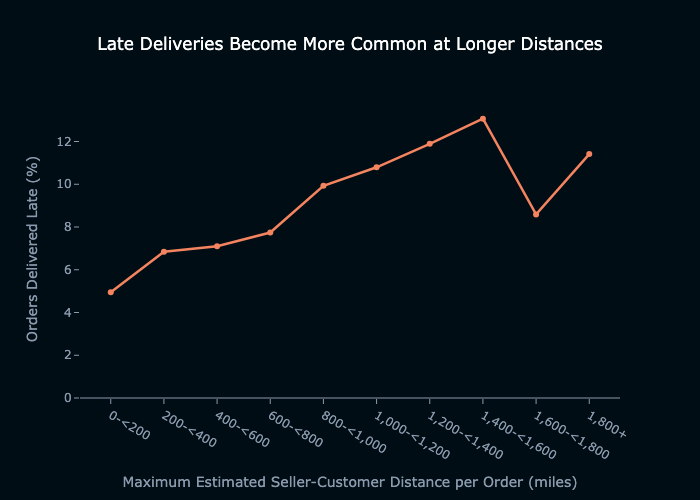

In [29]:
late_rate_by_distance = (
    distance_late.groupby("distance_bin", observed=True)
    .agg(
        late_rate=("delivered_on_time", lambda s: (~s.astype(bool)).mean() * 100),
        n=("order_id", "size"),
    )
    .reset_index()
)

bin_labels = [
    f"{b.left:,.0f}+"
    if np.isinf(b.right)
    else f"{b.left:,.0f}-<{b.right:,.0f}"
    for b in late_rate_by_distance["distance_bin"]
]

fig = go.Figure(go.Scatter(
    x=bin_labels,
    y=late_rate_by_distance["late_rate"],
    mode="lines+markers",
    line=dict(color=CORAL, width=2.5),
    marker=dict(size=6),
))

fig.update_layout(
    template=custom_dark, 
    title="Late Deliveries Become More Common at Longer Distances", 
    showlegend=False
)
fig.update_xaxes(title_text="Maximum Estimated Seller-Customer Distance per Order (miles)", type="category", showgrid=False)
fig.update_yaxes(title_text="Orders Delivered Late (%)", rangemode="tozero", showgrid=False)
fig.show(renderer="png")

In [30]:
tests["5.4 Distance vs. lateness"] = chi_square_test(distance_late, "distance_bin", "delivered_on_time")
print(format_test_result(tests["5.4 Distance vs. lateness"]))

a statistically significant association (chi-square = 575.2, dof = 9, p < 0.001)
    effect size: Cramer's V = 0.077 (negligible)


In [31]:
print(late_rate_by_distance[["distance_bin", "late_rate", "n"]].round(1).to_string(index=False))

    distance_bin  late_rate     n
    [0.0, 200.0)        4.9 34040
  [200.0, 400.0)        6.8 30744
  [400.0, 600.0)        7.1 15620
  [600.0, 800.0)        7.7  4793
 [800.0, 1000.0)        9.9  3163
[1000.0, 1200.0)       10.8  1964
[1200.0, 1400.0)       11.9  3095
[1400.0, 1600.0)       13.1  2349
[1600.0, 1800.0)        8.6   524
   [1800.0, inf)       11.4   184


Late-delivery rates differ across distance bins (χ² = 575.2, df = 9, p < 0.001), but the overall association is negligible in size (Cramér’s V = 0.077). The late-delivery rate rises from about 5% for orders within 200 miles to about 13% at 1,400–1,600 miles, falls back to about 9% at 1,600–1,800 miles, and is about 11% in the longest group. At every distance, most orders still arrive on or before their estimated date.

### 5.5 Does freight cost scale with distance?

Longer distance orders generally take more time to arrive. Do they also tend to carry higher freight charges per item? Freight is recorded for each order item, so each item contributes once to the median for its estimated seller–customer distance range.

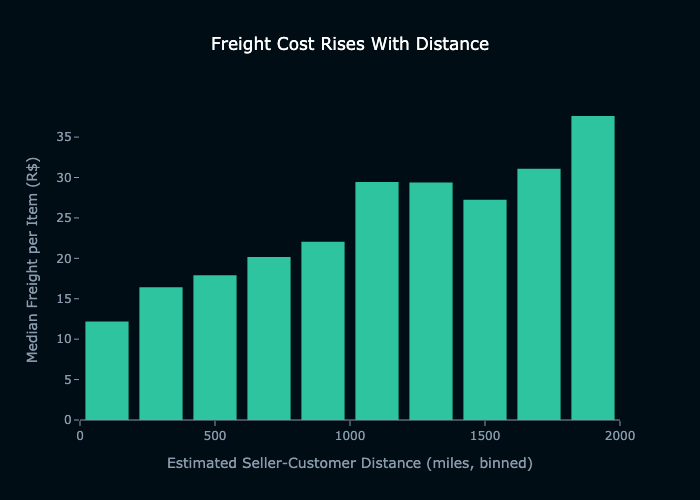

In [32]:
# Freight is recorded per order item, so each item contributes one observation.
freight_data = orders_with_items.dropna(subset=["customer_seller_distance_miles", "item_freight_value"])

freight_by_distance = binned_aggregate(
    freight_data, "customer_seller_distance_miles", "item_freight_value", min_n=MIN_BIN_N
)

fig = go.Figure(go.Bar(
    x=freight_by_distance["bin_mid"], y=freight_by_distance["value"],
    marker=dict(color=TEAL),
))
fig.update_layout(
    template=custom_dark, 
    title="Freight Cost Rises With Distance", 
    showlegend=False
)
fig.update_xaxes(title_text="Estimated Seller-Customer Distance (miles, binned)", showgrid=False)
fig.update_yaxes(title_text="Median Freight per Item (R$)", showgrid=False)
fig.show(renderer="png")

In [33]:
tests["5.5 Distance vs. freight"] = spearman_summary(
    freight_data["customer_seller_distance_miles"],
    freight_data["item_freight_value"],
    "Distance vs. freight value",
)
print(format_test_result(tests["5.5 Distance vs. freight"]))

Distance vs. freight value: a statistically significant correlation (Spearman rho = 0.63, n=112,650, p < 0.001, large)


Median freight per item roughly triples, from about R$12 for seller–customer distances under 200 miles to about R$38 at 1,800–2,000 miles. Across all 112,650 items, greater estimated distance is strongly associated with higher freight charges (Spearman’s ρ = 0.63). Longer waits and higher freight charges both accompany greater distance, yet most orders still arrive by their estimated date. How do customers rate their orders when they wait longer, pay more for shipping, or receive a delivery later than expected?

## 6. Drivers of Customer Satisfaction

Section 5 showed that longer distances come with longer waits, higher freight charges, and a somewhat higher chance of missing the delivery estimate. This section uses review scores to examine which of these is reflected in how customers rate their orders. Each order is counted once.

In [34]:
# Reviews and delivery outcomes belong to the order, so each order counts once regardless of how many items it had
order_reviews = (
    orders_with_items
    .drop_duplicates(subset="order_id")
    .dropna(subset=["order_review_1_score"])
)

### 6.1 Does missing the delivery estimate matter?

Only 6.8% of delivered orders arrive after the estimated date. Comparing their review scores with those of orders that arrive on or before the estimate shows whether late deliveries tend to receive lower ratings and how large the difference is.

                   mean  median  pct_one_star      n
delivered_on_time                                   
True               4.29     5.0          6.62  89448
False              2.27     1.0          53.7   6382


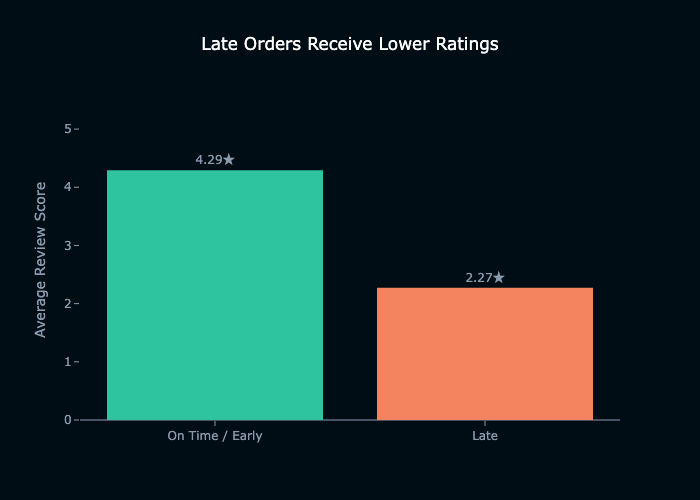

In [35]:
on_time_reviews = order_reviews.dropna(subset=["delivered_on_time"])

# Summary behind the chart and the caption
review_summary = on_time_reviews.groupby("delivered_on_time")["order_review_1_score"].agg(
    mean="mean",
    median="median",
    pct_one_star=lambda s: (s == 1).mean() * 100,
    n="size",
).reindex([True, False])
print(review_summary.round(2))

fig = go.Figure(go.Bar(
    x=["On Time / Early", "Late"], 
    y=review_summary["mean"],
    marker=dict(color=[PALETTE_ON_TIME[True], PALETTE_ON_TIME[False]]),
    text=[f"{v:.2f}★" for v in review_summary["mean"]],
    textposition="outside",
))
fig.update_layout(
    template=custom_dark, 
    title="Late Orders Receive Lower Ratings", 
    showlegend=False
)
fig.update_yaxes(title_text="Average Review Score", range=[0, 5.5], showgrid=False)
fig.show(renderer="png")

In [36]:
tests["6.1 On-time vs. late review"] = compare_two_groups(
    on_time_reviews.loc[on_time_reviews["delivered_on_time"] == True, "order_review_1_score"],
    on_time_reviews.loc[on_time_reviews["delivered_on_time"] == False, "order_review_1_score"],
    "On time / early",
    "Late",
)
print(format_test_result(tests["6.1 On-time vs. late review"], unit="\u2605"))

On time / early (median 5.00★, n=89,448) vs. Late (median 1.00★, n=6,382): a statistically significant difference (Mann-Whitney U = 467,353,878, p < 0.001)
    effect size: rank-biserial r = 0.637 (large)


More than half of reviewed orders that arrive late receive one star (53.7%), compared with 6.6% of those that arrive on or before the estimate. The median rating is 1 star for late orders and 5 stars for on-time orders. The difference in ratings is large (rank-biserial r = 0.64, Mann–Whitney p < 0.001).

### 6.2 Does wait time matter separately from lateness?

Late orders also tend to take longer. Among orders delivered within the same time range, do those that miss the estimate still receive lower ratings? Grouping orders by delivery duration also shows how ratings vary with wait time for on-time and late orders separately.

         mean             n        
arrival  Late On time  Late On time
dur_bin                            
0-3      4.83    4.46     6    8559
4-7      3.82    4.39    87   24889
8-14     3.26     4.3   341   35850
15-21    2.96    4.15   644   14620
22-30    2.49    3.92  2050    4776
30+      1.85    3.58  3254     754


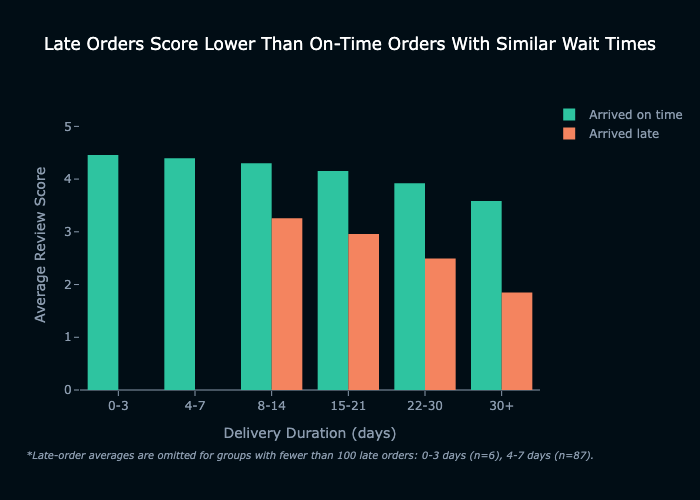

In [37]:
duration_bins = [0, 3, 7, 14, 21, 30, np.inf]
duration_labels = ["0-3", "4-7", "8-14", "15-21", "22-30", "30+"]

wait_reviews = (
    order_reviews.dropna(subset=["delivered_on_time", "delivery_duration_days"])
    .assign(
        dur_bin=lambda d: pd.cut(
            d["delivery_duration_days"], bins=duration_bins, labels=duration_labels, include_lowest=True
        ),
        arrival=lambda d: np.where(d["delivered_on_time"].astype(bool), "On time", "Late"),
    )
)

review_by_wait = (
    wait_reviews.groupby(["dur_bin", "arrival"], observed=True)["order_review_1_score"]
    .agg(mean="mean", n="size")
    .unstack("arrival")
)
print(review_by_wait.round(2))

# Hide averages based on too few orders
mean_scores = review_by_wait["mean"].where(review_by_wait["n"] >= MIN_BIN_N)

fig = go.Figure()
for label, on_time in [("On time", True), ("Late", False)]:
    fig.add_trace(go.Bar(
        x=mean_scores.index.astype(str), y=mean_scores[label],
        name=f"Arrived {label.lower()}", marker=dict(color=PALETTE_ON_TIME[on_time]),
    ))
fig.update_layout(
    template=custom_dark, 
    barmode="group", 
    title="Late Orders Score Lower Than On-Time Orders With Similar Wait Times"
)
fig.update_xaxes(title_text="Delivery Duration (days)")
fig.update_yaxes(
    title_text="Average Review Score", 
    range=[0, 5.5], 
    showgrid=False
)

# Note which late averages are hidden
late_counts = review_by_wait["n"]["Late"]
hidden = late_counts[late_counts < MIN_BIN_N]
hidden_note = ", ".join(f"{label} days (n={int(n)})" for label, n in hidden.items())

fig.add_annotation(
    text=f"<i>*Late-order averages are omitted for groups with fewer than {MIN_BIN_N} late orders: {hidden_note}.</i>",
    xref="paper", 
    yref="paper", 
    x=0.5, 
    y=-0.25, 
    xanchor="center",
    showarrow=False, 
    font=dict(color=LABEL, size=10),
)
fig.update_layout(margin=dict(b=110))
fig.show(renderer="png")

In [38]:
on_time_only = wait_reviews[wait_reviews["arrival"] == "On time"]
tests["6.2 Duration vs. review"] = compare_groups_kruskal(on_time_only, "dur_bin", "order_review_1_score")
print(format_test_result(tests["6.2 Duration vs. review"]))

Across 6 groups: a statistically significant difference (Kruskal-Wallis H = 1623.7, p < 0.001)
    effect size: eta-squared = 0.018 (small)


Even within the same delivery-duration range, late orders receive lower average ratings. Among orders delivered in 8–14 days, late orders average 3.26 stars, compared with 4.30 for on-time orders. The gap widens across all four ranges with enough orders to compare, from 1.04 stars at 8–14 days to 1.73 stars for deliveries taking more than 30 days.

Longer wait times are also associated with lower ratings among orders that meet their estimate. Average ratings fall from 4.46 stars for delivery within 3 days to 3.58 stars for delivery in more than 30 days. Differences across the six wait-time groups are statistically significant, with a small overall effect size (Kruskal–Wallis H = 1,623.7, p < 0.001, η² = 0.018).

### 6.3 Does freight cost matter as much as speed?

Shipping cost is the other part of the delivery experience. Freight burden measures total freight as a share of the order’s item subtotal. How much do average ratings vary across freight burden groups, and how does that gap compare with the one observed across wait times?

           mean      n
ratio_bin             
0-10%      4.14  15575
10-20%     4.13  28092
20-30%     4.12  19899
30-50%     4.08  18852
50-100%    4.08  12366
100%+      3.98   3133


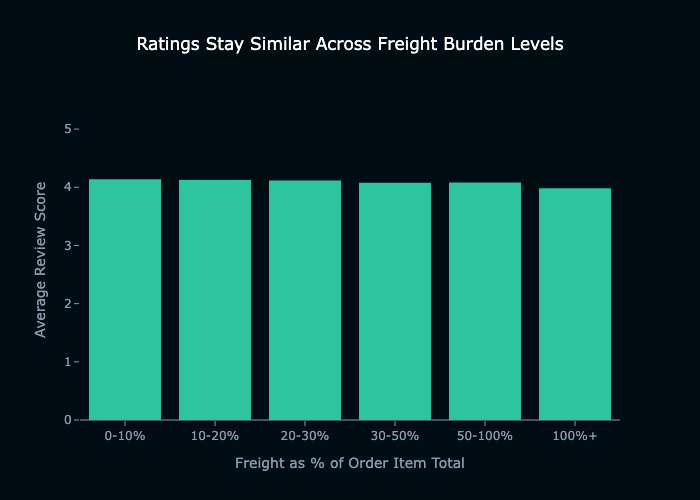

In [39]:
# Order-level freight burden: total freight as a share of the total item price
order_totals = orders_with_items.groupby("order_id")[["item_freight_value", "item_price"]].sum(min_count=1)
order_freight_ratio = order_totals["item_freight_value"] / order_totals["item_price"]

ratio_bins = [0, 0.1, 0.2, 0.3, 0.5, 1, np.inf]
ratio_labels = ["0-10%", "10-20%", "20-30%", "30-50%", "50-100%", "100%+"]

freight_reviews = (
    order_reviews.assign(order_freight_ratio=lambda d: d["order_id"].map(order_freight_ratio))
    .dropna(subset=["order_freight_ratio"])
    .assign(ratio_bin=lambda d: pd.cut(
        d["order_freight_ratio"], bins=ratio_bins, labels=ratio_labels, include_lowest=True
    ))
)

review_by_freight_ratio = freight_reviews.groupby("ratio_bin", observed=True)["order_review_1_score"].agg(mean="mean", n="size")
print(review_by_freight_ratio.round(2))

fig = go.Figure(go.Bar(
    x=review_by_freight_ratio.index.astype(str), 
    y=review_by_freight_ratio["mean"],
    marker=dict(color=TEAL),
))
fig.update_layout(
    template=custom_dark, 
    title="Ratings Stay Similar Across Freight Burden Levels", 
    showlegend=False
)
fig.update_xaxes(title_text="Freight as % of Order Item Total")
fig.update_yaxes(title_text="Average Review Score", range=[0, 5.5], showgrid=False)
fig.show(renderer="png")

In [40]:
tests["6.3 Freight burden vs. review"] = compare_groups_kruskal(freight_reviews, "ratio_bin", "order_review_1_score")
print(format_test_result(tests["6.3 Freight burden vs. review"]))

Across 6 groups: a statistically significant difference (Kruskal-Wallis H = 78.4, p < 0.001)
    effect size: eta-squared = 0.001 (negligible)


Average review scores vary little with freight burden. Orders with freight charges at or below 10% of the item total average 4.14 stars. Even when freight exceeds the item total, the average is 3.98 stars. This highest freight burden group accounts for about 3% of reviewed orders and is the only group to average below 4 stars.

Differences across the six groups are statistically significant (Kruskal–Wallis H = 78.4, p < 0.001), though the effect size is negligible (η² = 0.001). The 0.16-star gap between the lowest and highest freight burden groups is smaller than either delivery-related gap: 0.88 stars between the shortest and longest wait times among on-time orders, and 2.02 stars between on-time and late orders.

## 7. Product Characteristics and Shipping

Sections 5 and 6 focused on distance and the delivery estimate. This section turns to the products themselves and asks whether what is being shipped is related to how long delivery takes and what it costs.

### 7.1 Do heavier orders take longer to deliver, or only cost more to ship?

Heavier orders might be expected both to cost more to ship and to take longer to arrive. Comparing median freight and median delivery duration across order weight shows whether weight is associated with each. Each order is counted once, using the combined weight and freight of its items.

bin_mid  value     n
    0.5   15.2 57021
    1.5   17.9 16719
    2.5   21.5  6372
    3.5   25.3  3131
    4.5   22.8  2122
    5.5   26.2  2063
    6.5   24.6  2242
    7.5   27.4  1389
    8.5   29.2  1154
    9.5   27.4  1033
   10.5   31.0   919
   11.5   37.8   578
   12.5   43.6   474
   13.5   47.8   457
   14.5   50.8   276
   15.5   46.3   372
   16.5   37.9   433
   17.5   54.2   291
   18.5   54.4   171
   19.5   68.2   152
   20.5   67.2   166
   22.5   69.7   145
   29.5  104.1   266
bin_mid  value     n
    0.5    9.0 55735
    1.5   10.0 16409
    2.5   10.0  6213
    3.5   10.0  3055
    4.5   11.0  2066
    5.5   11.0  2021
    6.5   11.0  2190
    7.5   10.0  1367
    8.5   11.0  1128
    9.5   11.0  1018
   10.5   11.0   899
   11.5   11.0   565
   12.5   12.0   455
   13.5   12.0   440
   14.5   12.0   271
   15.5   12.0   357
   16.5   13.0   424
   17.5   12.0   288
   18.5   12.0   164
   19.5   10.0   150
   20.5   12.0   161
   22.5   11.0   144
   29.5   16.

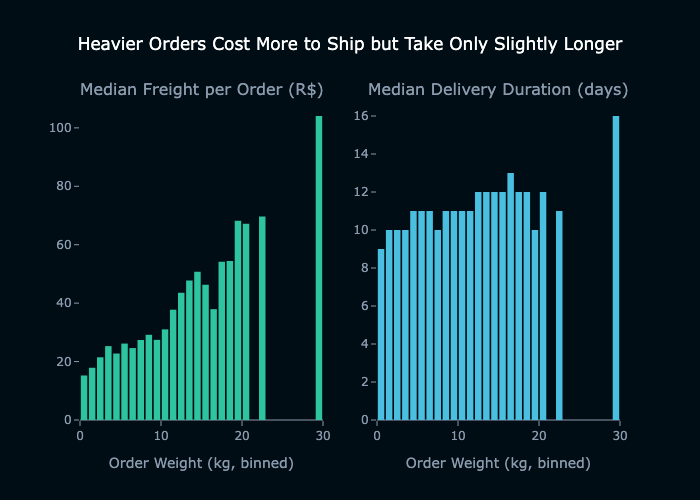

In [41]:
# One row per order: total weight, total freight, and delivery duration
order_totals = (
    orders_with_items.groupby("order_id")
    .agg(
        weight_g=("product_weight_g", "sum"),
        freight=("item_freight_value", "sum"),
        delivery_duration_days=("delivery_duration_days", "first"),
    )
    .reset_index()
)
order_totals["weight_kg"] = order_totals["weight_g"] / 1000
order_totals = order_totals[order_totals["weight_kg"] > 0]

delivered_totals = order_totals.dropna(subset=["delivery_duration_days"])

freight_by_weight = binned_aggregate(
    order_totals, 
    "weight_kg", 
    "freight", 
    width=1, 
    min_n=MIN_BIN_N
)
duration_by_weight = binned_aggregate(
    delivered_totals, 
    "weight_kg", 
    "delivery_duration_days", 
    width=1, 
    min_n=MIN_BIN_N
)

print(freight_by_weight[["bin_mid", "value", "n"]].round(1).to_string(index=False))
print(duration_by_weight[["bin_mid", "value", "n"]].round(1).to_string(index=False))

fig = make_subplots(rows=1, cols=2, subplot_titles=("Median Freight per Order (R$)", "Median Delivery Duration (days)"))
fig.add_trace(
    go.Bar(x=freight_by_weight["bin_mid"], y=freight_by_weight["value"], marker=dict(color=TEAL)),
    row=1, col=1,
)
fig.add_trace(
    go.Bar(x=duration_by_weight["bin_mid"], y=duration_by_weight["value"], marker=dict(color=SKY)),
    row=1, col=2,
)
fig.update_layout(
    template=custom_dark, 
    title="Heavier Orders Cost More to Ship but Take Only Slightly Longer", 
    showlegend=False

)
fig.update_xaxes(title_text="Order Weight (kg, binned)", showgrid=False)
fig.update_yaxes(rangemode="tozero", showgrid=False)
fig.show(renderer="png")

In [42]:
tests["7.1 Weight vs. freight"] = spearman_summary(
    order_totals["weight_kg"], order_totals["freight"], "Order weight vs. freight",
)
tests["7.1 Weight vs. duration"] = spearman_summary(
    delivered_totals["weight_kg"], delivered_totals["delivery_duration_days"], "Order weight vs. delivery duration",
)
print(format_test_result(tests["7.1 Weight vs. freight"]))
print(format_test_result(tests["7.1 Weight vs. duration"]))

Order weight vs. freight: a statistically significant correlation (Spearman rho = 0.49, n=98,660, p < 0.001, medium)
Order weight vs. delivery duration: a statistically significant correlation (Spearman rho = 0.09, n=96,470, p < 0.001, negligible)


Median freight per order rises with weight, from R$15 for orders under 1 kg to about R$68 at 19–23 kg and R$104 for the group at 29–30 kg (Spearman’s ρ = 0.49). Median delivery duration changes far less: 9 days for orders under 1 kg, 10 to 13 days between 1 and 23 kg, and 16 days in the heaviest group (ρ = 0.09). Weight is moderately associated with shipping cost but has a negligible association with delivery time, in contrast to distance (ρ = 0.54 in 5.2). Most orders are light, with 58% under 1 kg. Weight groups with fewer than 100 orders are omitted, which leaves gaps above 21 kg.

### 7.2 Which product categories take longest to deliver?

Weight has little relationship with delivery time, but product type might still matter, for example if some categories need more preparation or special handling. Comparing median delivery duration across categories shows how much it varies by type of product. An order is counted once in each category it contains.

Categories with at least 200 orders: 43
Median delivery duration ranges from 7 to 18 days
                                         median  mean     n
product_category_english                                   
office_furniture                           18.0  20.2  1254
fashion_shoes                              14.0  15.2   235
furniture_living_room                      11.5  13.4   414
home_appliances_2                          11.0  13.4   227
consoles_games                             11.0  13.3  1018
home_confort                               11.0  13.2   392
garden_tools                               11.0  13.2  3448
home_construction                          11.0  13.0   483
computers_accessories                      11.0  12.7  6529
audio                                      10.0  13.0   348
furniture_decor                            10.0  12.6  6307
musical_instruments                        10.0  12.6   611
bed_bath_table                             10.0  12.5  9272
telephony 

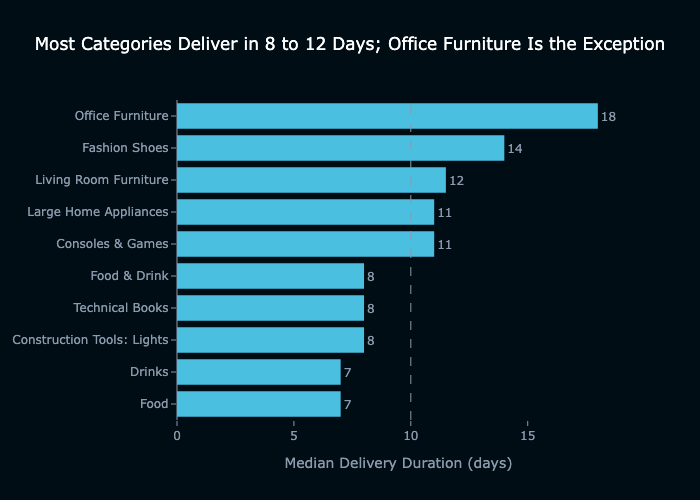

In [43]:
MIN_CATEGORY_ORDERS = 200


# One row per order and category; an order with two categories appears in both
category_orders = (
    orders_with_items.dropna(subset=["product_category_english", "delivery_duration_days"])
    .drop_duplicates(subset=["order_id", "product_category_english"])
)

duration_by_category = (
    category_orders.groupby("product_category_english", observed=True)["delivery_duration_days"]
    .agg(median="median", mean="mean", n="size")
    .query("n >= @MIN_CATEGORY_ORDERS")
    .sort_values(["median", "mean"], ascending=False)
)

print(f"Categories with at least {MIN_CATEGORY_ORDERS} orders: {len(duration_by_category)}")
print(f"Median delivery duration ranges from {duration_by_category['median'].min():.0f} to {duration_by_category['median'].max():.0f} days")
print(duration_by_category.round(1).to_string())

shown = pd.concat([duration_by_category.head(5), duration_by_category.tail(5)])

CATEGORY_LABELS = {
    # Olist does not document this split; the "_2" group has a median weight of 7.5 kg against 0.5 kg
    "home_appliances_2": "Large Home Appliances",
    "furniture_living_room": "Living Room Furniture",
    "consoles_games": "Consoles & Games",
    "food_drink": "Food & Drink",
    "books_technical": "Technical Books",
    "construction_tools_lights": "Construction Tools: Lights",
}

category_labels = [CATEGORY_LABELS.get(name, name.replace("_", " ").title()) for name in shown.index]
overall_median = orders_unique["delivery_duration_days"].median()

fig = go.Figure(go.Bar(
    x=shown["median"],
    y=category_labels,
    orientation="h",
    marker=dict(color=SKY),
    text=[f"{v:.0f}" for v in shown["median"]],
    textposition="outside",
))
fig.add_vline(x=overall_median, line=dict(color=LABEL, width=1, dash="dash"))
fig.update_layout(
    template=custom_dark, 
    title="Most Categories Deliver in 8 to 12 Days; Office Furniture Is the Exception", 
    showlegend=False
)
fig.update_xaxes(title_text="Median Delivery Duration (days)", showgrid=False)
fig.update_yaxes(autorange="reversed")
fig.show(renderer="png")

In [44]:
tests["7.2 Category vs. duration"] = compare_groups_kruskal(
    category_orders, "product_category_english", "delivery_duration_days", min_n=MIN_CATEGORY_ORDERS,
)
print(format_test_result(tests["7.2 Category vs. duration"]))

Across 43 groups: a statistically significant difference (Kruskal-Wallis H = 2210.2, p < 0.001)
    effect size: eta-squared = 0.023 (small)


Median delivery duration varies little across most product categories. Among the 43 categories with at least 200 orders, all but four have medians between 8 and 12 days, close to the overall median of 10. Office furniture is the clear exception at 18 days, followed by fashion shoes at 14, while food and drinks are fastest at 7. Differences across categories are statistically significant but small (Kruskal–Wallis H = 2,210.2, p < 0.001; η² = 0.023). Some of the variation may reflect where a category’s sellers are located rather than the products themselves.

## 8. Trends Over Time

Sections 5 through 7 treated the data as a single period. Olist’s order volume grew substantially between 2017 and 2018, so this section looks at whether delivery times and late-delivery rates changed as it did.

In [45]:
# 2016 and the final weeks of the data are sparse or incomplete, so trends use January 2017 to August 2018
TREND_START, TREND_END = "2017-01-01", "2018-09-01"

purchase_time = orders_unique["order_purchase_timestamp"]
orders_trend = orders_unique[(purchase_time >= TREND_START) & (purchase_time < TREND_END)]

print(f"{len(orders_unique):,} orders, {len(orders_trend):,} in the trend window")

98,666 orders, 98,353 in the trend window


In [46]:
# Daily order counts at the end of the data: volume tapers off from 22 August 2018
daily_orders = orders_unique.set_index("order_purchase_timestamp").resample("D").size()
print(daily_orders.loc["2018-08-13":"2018-09-03"].to_string())

order_purchase_timestamp
2018-08-13    288
2018-08-14    315
2018-08-15    285
2018-08-16    318
2018-08-17    255
2018-08-18    196
2018-08-19    204
2018-08-20    252
2018-08-21    239
2018-08-22    186
2018-08-23    142
2018-08-24     98
2018-08-25     69
2018-08-26     73
2018-08-27     66
2018-08-28     39
2018-08-29     11
2018-08-30      0
2018-08-31      0
2018-09-01      0
2018-09-02      0
2018-09-03      1
Freq: D


August 2018 is incomplete. Daily orders taper off after 21 August, so its total understates that month’s volume.

### 8.1 How fast did order volume grow?

Order volume sets the context for delivery performance, since a growing marketplace handles more shipments each month.

     month  value
2017-01-01    789
2017-02-01   1733
2017-03-01   2641
2017-04-01   2391
2017-05-01   3660
2017-06-01   3217
2017-07-01   3969
2017-08-01   4293
2017-09-01   4243
2017-10-01   4568
2017-11-01   7451
2017-12-01   5624
2018-01-01   7220
2018-02-01   6694
2018-03-01   7188
2018-04-01   6934
2018-05-01   6853
2018-06-01   6160
2018-07-01   6273
2018-08-01   6452


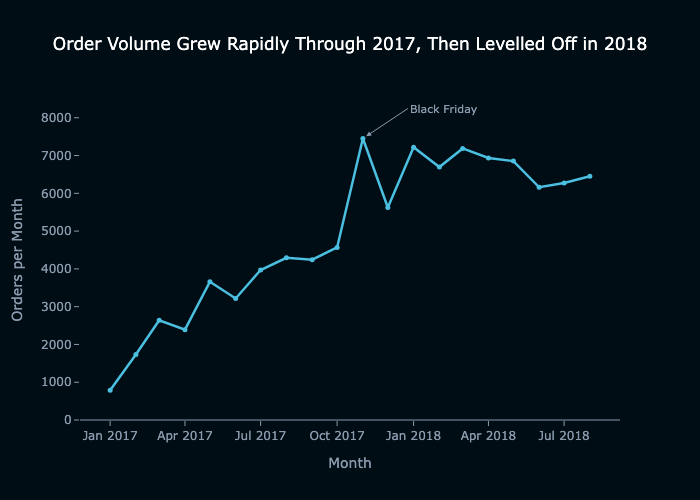

In [47]:
volume_by_month = monthly_aggregate(orders_trend, "order_purchase_timestamp", "order_id", agg="size")
print(volume_by_month[["month", "value"]].to_string(index=False))

fig = build_time_series_chart(
    volume_by_month,
    title="Order Volume Grew Rapidly Through 2017, Then Levelled Off in 2018",
    y_label="Orders per Month",
    color=SKY,
)
fig.add_annotation(
    x="2017-11-01", y=volume_by_month.loc[volume_by_month["month"] == "2017-11-01", "value"].iloc[0],
    text="Black Friday", xanchor="left",
    showarrow=True, arrowhead=2, arrowsize=1, arrowwidth=1, arrowcolor=LABEL, standoff=4,
    font=dict(color=LABEL, size=11), ax=45, ay=-30,
)
fig.update_xaxes(showgrid=False)
fig.update_yaxes(rangemode="tozero")
fig.show(renderer="png")

Monthly orders rise from about 800 in January 2017 to about 4,600 in October 2017, then jump to about 7,500 in November 2017, the month of Black Friday and the highest in the period. From January 2018 onward, volume holds between roughly 6,200 and 7,200 orders a month without further growth.

### 8.2 Did delivery performance change over the period?

Monthly late-delivery rates and delivery durations show whether performance held steady as order volume grew. Orders are grouped by the month in which they were purchased.

     month  late_rate  median_duration  median_days_early    n
2017-01-01        2.9             10.0               29.0  750
2017-02-01        3.0             10.0               20.0 1653
2017-03-01        4.6             10.0               14.0 2546
2017-04-01        6.6             12.0               14.0 2303
2017-05-01        3.0              9.0               14.0 3545
2017-06-01        3.0             10.0               13.0 3135
2017-07-01        2.8             10.0               13.0 3872
2017-08-01        2.9              9.0               13.0 4193
2017-09-01        4.4             10.0               12.0 4150
2017-10-01        4.2             10.0               12.0 4478
2017-11-01       12.4             12.0               10.0 7288
2017-12-01        7.5             13.0               14.0 5513
2018-01-01        5.7             11.0               14.0 7069
2018-02-01       14.1             14.0               10.0 6556
2018-03-01       19.0             13.0                8

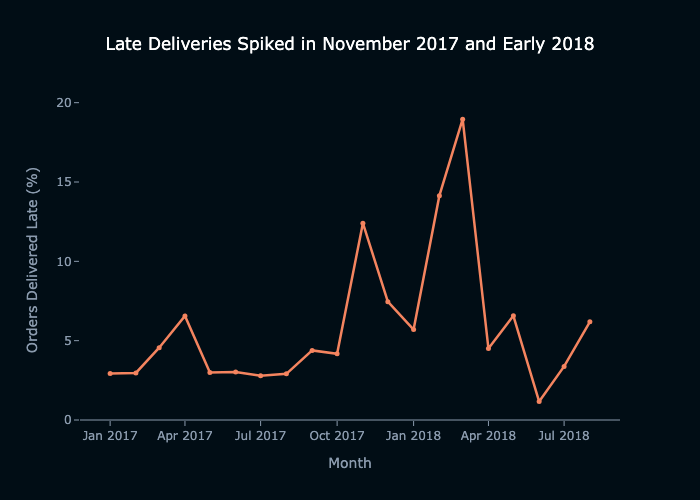

In [48]:
delivered_trend = orders_trend.dropna(subset=["delivered_on_time", "delivery_duration_days", "delivery_delay_days"])

late_rate_by_month = monthly_aggregate(
    delivered_trend, "order_purchase_timestamp", "delivered_on_time",
    agg=lambda s: (~s.astype(bool)).mean() * 100,
)
duration_by_month = monthly_aggregate(delivered_trend, "order_purchase_timestamp", "delivery_duration_days", agg="median")
days_early_by_month = monthly_aggregate(delivered_trend, "order_purchase_timestamp", "delivery_delay_days", agg="median")

monthly_delivery = pd.DataFrame({
    "month": late_rate_by_month["month"],
    "late_rate": late_rate_by_month["value"].round(1),
    "median_duration": duration_by_month["value"],
    "median_days_early": -days_early_by_month["value"],
    "n": late_rate_by_month["n"],
})
print(monthly_delivery.to_string(index=False))

fig = build_time_series_chart(
    late_rate_by_month,
    title="Late Deliveries Spiked in November 2017 and Early 2018",
    y_label="Orders Delivered Late (%)",
    color=CORAL,
)
fig.update_xaxes(showgrid=False)
fig.update_yaxes(rangemode="tozero")
fig.show(renderer="png")

The late-delivery rate stays near 3% for most of 2017, then rises sharply twice: to 12.4% for orders placed in November 2017, and to 14.1% and 19.0% for those placed in February and March 2018. It falls back to 4.5% in April 2018. Order volume remains at a similar level after April, so volume alone does not account for the spikes.

     month  value
2017-01-01   39.0
2017-02-01   30.0
2017-03-01   23.0
2017-04-01   26.0
2017-05-01   23.0
2017-06-01   24.0
2017-07-01   23.0
2017-08-01   23.0
2017-09-01   22.0
2017-10-01   23.0
2017-11-01   23.0
2017-12-01   28.0
2018-01-01   26.0
2018-02-01   24.0
2018-03-01   22.0
2018-04-01   24.0
2018-05-01   22.0
2018-06-01   28.0
2018-07-01   20.0
2018-08-01   14.0


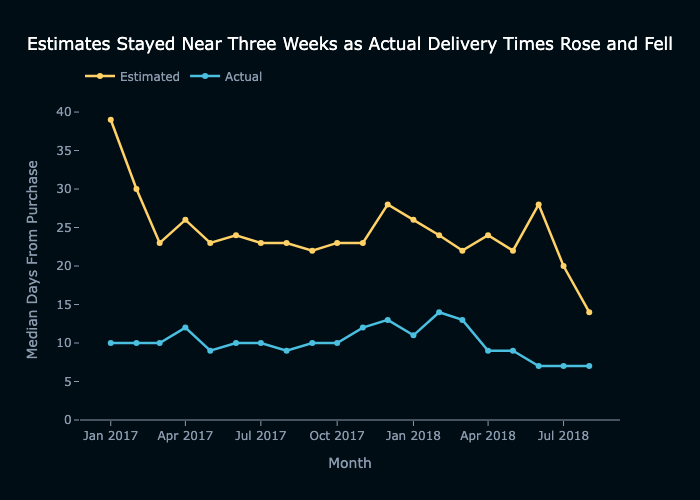

In [49]:
promised_by_month = monthly_aggregate(
    delivered_trend.assign(promised_days=lambda d: d["delivery_duration_days"] - d["delivery_delay_days"]),
    "order_purchase_timestamp", "promised_days", agg="median",
)
print(promised_by_month[["month", "value"]].to_string(index=False))

fig = go.Figure()
fig.add_trace(go.Scatter(
    x=promised_by_month["month"], 
    y=promised_by_month["value"],
    mode="lines+markers", 
    line=dict(color=YELLOW, width=2.5), 
    name="Estimated",
))
fig.add_trace(go.Scatter(
    x=duration_by_month["month"], 
    y=duration_by_month["value"],
    mode="lines+markers", 
    line=dict(color=SKY, width=2.5), 
    name="Actual",
))
fig.update_layout(
    template=custom_dark, 
    title="Estimates Stayed Near Three Weeks as Actual Delivery Times Rose and Fell", 
    legend=dict(orientation="h", y=1.12, x=0)
)
fig.update_xaxes(title_text="Month", showgrid=False)
fig.update_yaxes(title_text="Median Days From Purchase", rangemode="tozero", showgrid=False)
fig.show(renderer="png")

From March 2017 to May 2018, the median estimate stays between 22 and 26 days in most months, while the median actual delivery time rises from 9–10 days to 12–14 days between November 2017 and March 2018, then falls back to 9. The late-delivery spikes fall in the months where the buffer is thinnest: the median order arrives 10 days early in November 2017 and February 2018 and 8 days early in March 2018, compared with 12 to 14 days in most other months.

In mid-2018 the median actual delivery time falls to 7 days. The estimate is 28 days in June, when only 1.2% of orders are late, then drops to 20 and 14 days in July and August, when the late rate rises to 6.2% although deliveries are no slower.

## 9. Seller Differences in Time to Handoff

Section 5.2 showed that the median time from purchase to carrier handoff stays close to two days across distance ranges. That stage happens before shipping, so it may vary by seller. How much does it vary from seller to seller? For each seller, the median time from purchase to handoff is calculated, counting each order once for that seller. Only sellers with at least 30 such orders are included.

Sellers with at least 30 orders: 632 of 2,974
Share of qualifying order-seller pairs: 83.7%
Seller median handoff time: 10th percentile 1.2 days | 25th 1.5 | median 2.1 | 75th 3.1 | 90th 4.7


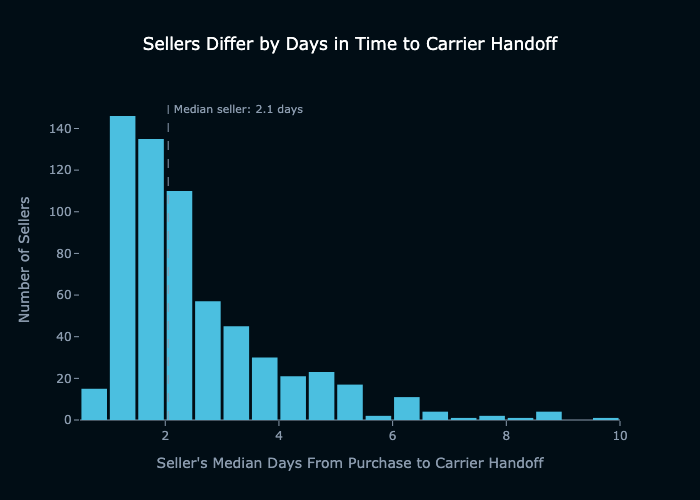

In [50]:
MIN_SELLER_ORDERS = 30

# One row per order and seller, with days from purchase to carrier handoff
# (fractional days, for the same reason as in 5.2)
seller_orders = (
    orders_with_items.drop_duplicates(subset=["order_id", "seller_id"])
    .dropna(subset=["order_purchase_timestamp", "order_delivered_carrier_date"])
    .assign(handoff_days=lambda d: (d["order_delivered_carrier_date"] - d["order_purchase_timestamp"]) / ONE_DAY)
)
seller_orders = seller_orders[seller_orders["handoff_days"] >= 0]

seller_handoff = (
    seller_orders.groupby("seller_id")["handoff_days"]
    .agg(median="median", n="size")
    .query("n >= @MIN_SELLER_ORDERS")
)

p10, p25, p50, p75, p90 = seller_handoff["median"].quantile([0.10, 0.25, 0.50, 0.75, 0.90])
print(f"Sellers with at least {MIN_SELLER_ORDERS} orders: {len(seller_handoff):,} of {seller_orders['seller_id'].nunique():,}")
print(f"Share of qualifying order-seller pairs: {seller_handoff['n'].sum() / len(seller_orders) * 100:.1f}%")
print(f"Seller median handoff time: 10th percentile {p10:.1f} days | 25th {p25:.1f} | median {p50:.1f} | 75th {p75:.1f} | 90th {p90:.1f}")

# Limit range for visibility in the chart
shown = seller_handoff[seller_handoff["median"] <= seller_handoff["median"].quantile(0.99)]

fig = go.Figure(go.Histogram(x=shown["median"], xbins=dict(start=0, size=0.5), marker=dict(color=SKY)))
fig.add_vline(x=p50, line=dict(color=LABEL, width=1, dash="dash"))
fig.add_annotation(
    x=p50, 
    y=1, 
    yref="paper", 
    xanchor="left", 
    showarrow=False,
    text=f" Median seller: {p50:.1f} days", 
    font=dict(color=LABEL, size=11),
)
fig.update_layout(
    template=custom_dark, 
    title="Sellers Differ by Days in Time to Carrier Handoff", 
    showlegend=False, 
    bargap=0.1
)
fig.update_xaxes(title_text="Seller's Median Days From Purchase to Carrier Handoff", showgrid=False)
fig.update_yaxes(title_text="Number of Sellers", showgrid=False)
fig.show(renderer="png")

Among the 632 sellers with at least 30 qualifying orders, who together account for 83.7% of order–seller pairs with usable handoff times, the typical time from purchase to carrier handoff varies several-fold. The median seller takes 2.1 days. A quarter of sellers take 1.5 days or less, a quarter take 3.1 days or more, and the slowest tenth take 4.7 days or more. Time before handoff therefore differs between sellers by several days, a meaningful share of a 10-day median delivery, though less than the difference in carrier transit between short and long distances (5.2). The measure starts at purchase, so it includes payment approval, which sellers do not control. The slowest 1% of sellers are omitted from the chart.

## 10. What Customers Write About

Section 6 showed that orders arriving after the estimated date receive lower ratings, even among orders with similar delivery times. About 40,000 of the 98,000 reviewed orders (41%) also include a written review in Portuguese. Do customers mention delivery timing when they explain their ratings?

In [51]:
# One row per order with a written review
reviews_text = order_reviews.dropna(subset=["order_review_1_message"]).copy()
reviews_text = reviews_text[reviews_text["order_review_1_message"].str.strip() != ""]
reviews_text["order_review_1_message"] = reviews_text["order_review_1_message"].str.replace(
    r"\bnao\b", "não", regex=True, case=False
)

reviews_text["score_bucket"] = np.select(
    [reviews_text["order_review_1_score"] <= 2, reviews_text["order_review_1_score"] >= 4],
    ["Negative (1-2 stars)", "Positive (4-5 stars)"],
    default="Neutral (3 stars)",
)

print(f"{len(reviews_text):,} of {len(order_reviews):,} reviewed orders include review text")
print(reviews_text["score_bucket"].value_counts().to_string())

40,240 of 97,917 reviewed orders include review text
score_bucket
Positive (4-5 stars)    26357
Negative (1-2 stars)    10371
Neutral (3 stars)        3512


### 10.1 Which words distinguish negative reviews from positive ones?

Positive reviews (4–5 stars) outnumber negative reviews (1–2 stars), so a word can appear more often in positive reviews simply because that group is larger. To identify words that are especially common in either group, this analysis uses weighted log-odds with an informative Dirichlet prior. This method accounts for group size and reduces the influence of rare words. The analysis keeps negation words such as não (“not”), since they can change the meaning of a comment, and excludes the placeholder names Olist used in place of company names.

Positive (4-5 stars) [('prazo', np.float64(-50.3)), ('antes', np.float64(-40.8)), ('recomendo', np.float64(-37.5)), ('bom', np.float64(-37.3)), ('bem', np.float64(-31.2)), ('entrega', np.float64(-29.9)), ('chegou', np.float64(-28.1)), ('qualidade', np.float64(-24.4)), ('super', np.float64(-23.0)), ('gostei', np.float64(-21.0)), ('dentro', np.float64(-20.2)), ('boa', np.float64(-18.4))]
Negative (1-2 stars) [('não', np.float64(70.3)), ('recebi', np.float64(35.4)), ('até', np.float64(22.7)), ('ainda', np.float64(22.6)), ('agora', np.float64(19.4)), ('quero', np.float64(17.5)), ('nem', np.float64(17.5)), ('apenas', np.float64(17.4)), ('contato', np.float64(17.0)), ('dois', np.float64(16.9)), ('nada', np.float64(16.7)), ('aguardando', np.float64(16.1))]


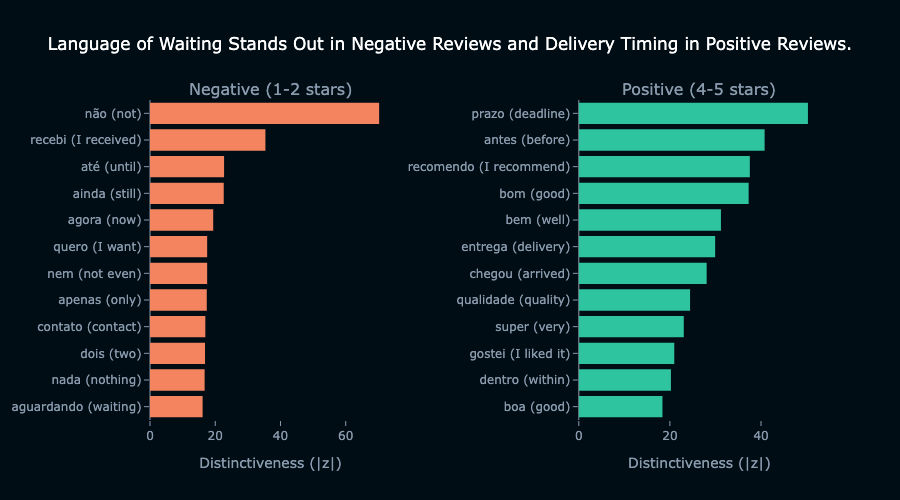

In [52]:
distinctive = distinctive_words(
    reviews_text, 
    "order_review_1_message",
    "score_bucket",
    group_a="Negative (1-2 stars)", 
    group_b="Positive (4-5 stars)", 
    n=12,
)

for bucket, words in distinctive.items():
    print(bucket, [(word, round(score, 1)) for word, score in words])

WORD_GLOSS = {
    "não": "not", 
    "recebi": "I received", 
    "até": "until", 
    "ainda": "still", 
    "agora": "now",
    "quero": "I want", 
    "nem": "not even", 
    "apenas": "only", 
    "contato": "contact",
    "dois": "two", 
    "nada": "nothing",
    "prazo": "deadline", 
    "antes": "before", 
    "recomendo": "I recommend", 
    "bom": "good",
    "bem": "well", 
    "entrega": "delivery", 
    "chegou": "arrived", 
    "qualidade": "quality",
    "super": "very", 
    "gostei": "I liked it", 
    "dentro": "within", 
    "boa": "good", 
    "aguardando": "waiting",
}

def with_gloss(word):
    return f"{word} ({WORD_GLOSS[word]})" if word in WORD_GLOSS else word

fig = make_subplots(
    rows=1, cols=2,
    subplot_titles=("Negative (1-2 stars)", "Positive (4-5 stars)"),
    horizontal_spacing=0.28,
)

for col, (bucket, color) in enumerate(
    [("Negative (1-2 stars)", CORAL), ("Positive (4-5 stars)", TEAL)], start=1
):
    words, scores = zip(*reversed(distinctive[bucket]))
    fig.add_trace(
        go.Bar(
            x=[abs(s) for s in scores], 
            y=[with_gloss(w) for w in words], 
            orientation="h",
            marker=dict(color=color), 
            showlegend=False
        ),
        row=1, col=col,
    )

fig.update_layout(
    template=custom_dark, 
    title="Language of Waiting Stands Out in Negative Reviews and Delivery Timing in Positive Reviews.", 
    height=500, 
    width=900
)
fig.update_xaxes(title_text="Distinctiveness (|z|)", showgrid=False)
fig.show(renderer="png")

In negative reviews, não (“not”) and recebi (“I received”) stand out most. Words such as ainda (“still”) and aguardando (“waiting”) also point to customers waiting for an order. In positive reviews, prazo (“deadline”) and antes (“before”) stand out most, alongside words of praise such as recomendo (“I recommend”). The examples below show how customers use these words to describe their experiences.

### 10.2 Example reviews

The selected reviews below show how customers use these words in context. Each Portuguese comment appears alongside an English translation. The examples were chosen for illustration and do not form a random sample.

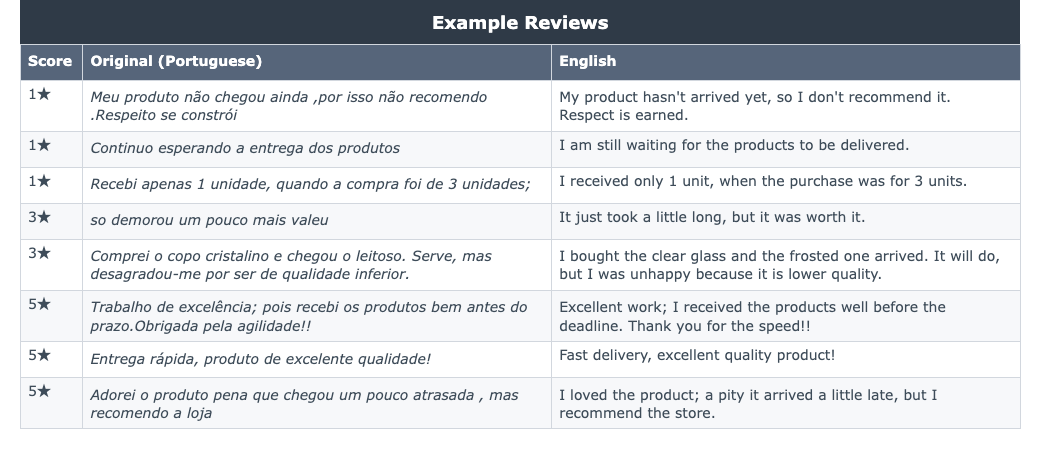

In [53]:
SAMPLE_REVIEWS = [
    (1, "Meu produto não chegou ainda ,por isso não recomendo .Respeito se constrói",
        "My product hasn't arrived yet, so I don't recommend it. Respect is earned."),
    (1, "Continuo esperando a entrega dos produtos",
        "I am still waiting for the products to be delivered."),
    (1, "Recebi apenas 1 unidade, quando a compra foi de 3 unidades;",
        "I received only 1 unit, when the purchase was for 3 units."),
    (3, "so demorou um pouco mais valeu",
        "It just took a little long, but it was worth it."),
    (3, "Comprei o copo cristalino e chegou o leitoso. Serve, mas desagradou-me por ser de qualidade inferior.",
        "I bought the clear glass and the frosted one arrived. It will do, but I was unhappy because it is lower quality."),
    (5, "Trabalho de excelência; pois recebi os produtos bem antes do prazo.Obrigada pela agilidade!!",
        "Excellent work; I received the products well before the deadline. Thank you for the speed!!"),
    (5, "Entrega rápida, produto de excelente qualidade!",
        "Fast delivery, excellent quality product!"),
    (5, "Adorei o produto pena que chegou um pouco atrasada , mas recomendo a loja",
        "I loved the product; a pity it arrived a little late, but I recommend the store."),
]

display_stylized_table(
    title="Example Reviews",
    headers=("Score", "Original (Portuguese)", "English"),
    rows=[(f"{score}★", f"<em>{original}</em>", english) for score, original, english in SAMPLE_REVIEWS],
)

The one-star reviews describe orders that had yet to arrive or arrived with items missing. Among the five-star reviews, one praises delivery well before the deadline and another praises fast delivery. Other comments show why timing tells only part of the story. One customer gives three stars and discusses product quality. Another gives five stars despite a late arrival and still recommends the store.

## 11. Delivery Experience and Repeat Purchases

Late deliveries receive lower ratings, and delivery timing stands out in the written reviews. Does that experience also show up in customers’ purchasing behavior? This section examines how often customers order again and whether those whose first order arrived late are less likely to return.

### 11.1 How many customers order again?

A customer is counted as returning if they placed more than one distinct order during the observation period.

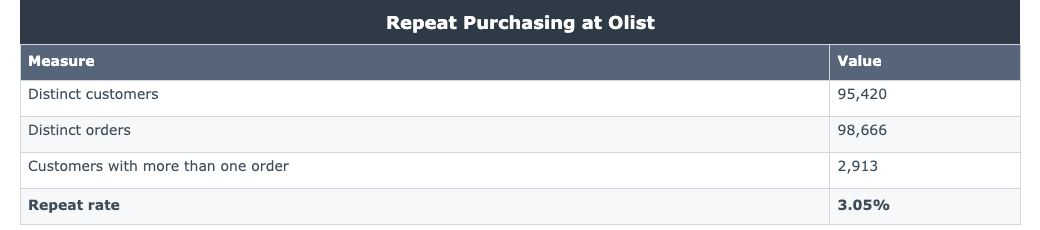

In [54]:
orders_per_customer = orders_unique.groupby("customer_unique_id")["order_id"].nunique()
repeat_rate = (orders_per_customer > 1).mean() * 100

display_stylized_table(
    title="Repeat Purchasing at Olist",
    headers=("Measure", "Value"),
    rows=[
        ("Distinct customers", f"{orders_per_customer.size:,}"),
        ("Distinct orders", f"{len(orders_unique):,}"),
        ("Customers with more than one order", f"{(orders_per_customer > 1).sum():,}"),
        ("<b>Repeat rate</b>", f"<b>{repeat_rate:.2f}%</b>"),
    ],
)


In [55]:
# How many repeat customers placed their second order before the first one arrived?
customer_orders = orders_unique.sort_values("order_purchase_timestamp")
order_rank = customer_orders.groupby("customer_unique_id").cumcount()
first_orders = customer_orders[order_rank == 0].copy()
second_order_time = customer_orders[order_rank == 1].set_index("customer_unique_id")["order_purchase_timestamp"]

repeaters = first_orders[
    first_orders["customer_unique_id"].isin(second_order_time.index)
].dropna(subset=["order_delivered_customer_date"])

before_delivery = (
    repeaters["customer_unique_id"].map(second_order_time) < repeaters["order_delivered_customer_date"]
)

print(f"{before_delivery.sum():,} of {len(repeaters):,} repeat customers with a delivered first order "
      f"({before_delivery.mean():.1%}) placed their second order before the first one arrived.")

1,088 of 2,838 repeat customers with a delivered first order (38.3%) placed their second order before the first one arrived.


Of 95,420 customers, 2,913 placed more than one order during the period, a repeat rate of 3.05%. Among the 2,838 repeat customers whose first order was delivered, 1,088 (38.3%) placed their second order before it arrived. The next comparison therefore starts the clock at the first delivery and counts any subsequent purchase within 180 days.

### 11.2 Is a late first order associated with a lower chance of returning?

This analysis compares 180-day repeat purchase rates for customers whose first order arrived on time and those whose first order arrived late. The window begins when the first order is delivered. Because recorded order volume tapers off starting August 22, 2018, only customers with a full 180 days of follow-up by that cutoff are included.

                   rate      n
delivered_on_time             
True               1.85  48118
False              1.38   2532


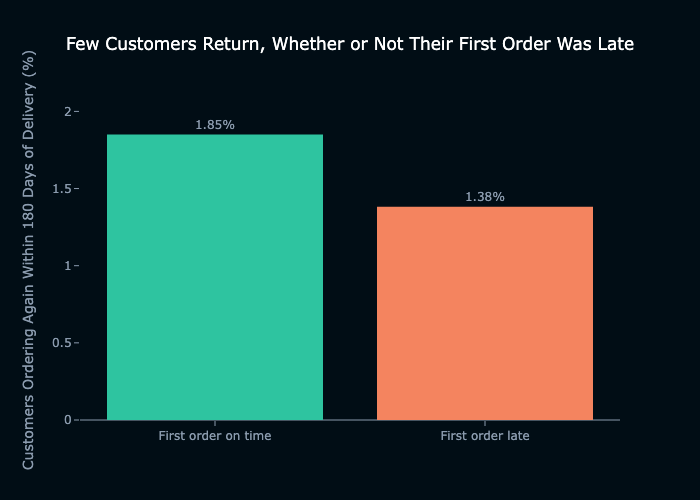

In [56]:
RETURN_WINDOW_DAYS = 180

customer_orders = orders_unique.sort_values("order_purchase_timestamp")
order_rank = customer_orders.groupby("customer_unique_id").cumcount()
first_orders = customer_orders[order_rank == 0].copy()

# Each customer's earliest order placed after their first order was delivered
first_delivered = first_orders.set_index("customer_unique_id")["order_delivered_customer_date"]
placed_after_delivery = customer_orders[
    customer_orders["order_purchase_timestamp"] > customer_orders["customer_unique_id"].map(first_delivered)
]
next_order_time = placed_after_delivery.groupby("customer_unique_id")["order_purchase_timestamp"].min()

days_to_return = (
    first_orders["customer_unique_id"].map(next_order_time) - first_orders["order_delivered_customer_date"]
) / ONE_DAY
first_orders["returned"] = days_to_return <= RETURN_WINDOW_DAYS

# Daily orders taper off from 22 August 2018, so follow-up ends there
FOLLOW_UP_END = pd.Timestamp("2018-08-22")  
cutoff = FOLLOW_UP_END - pd.Timedelta(days=RETURN_WINDOW_DAYS)
observed = first_orders[first_orders["order_delivered_customer_date"] <= cutoff].dropna(subset=["delivered_on_time"])

return_by_outcome = (
    observed.groupby("delivered_on_time")["returned"]
    .agg(rate=lambda s: s.mean() * 100, n="size")
    .reindex([True, False])
)
print(return_by_outcome.round(2))

fig = go.Figure(go.Bar(
    x=["First order on time", "First order late"], 
    y=return_by_outcome["rate"],
    marker=dict(color=[PALETTE_ON_TIME[True], PALETTE_ON_TIME[False]]),
    text=[f"{v:.2f}%" for v in return_by_outcome["rate"]], 
    textposition="outside",
))
fig.update_layout(
    template=custom_dark, 
    title="Few Customers Return, Whether or Not Their First Order Was Late", 
    showlegend=False
)
fig.update_yaxes(
    title_text=f"Customers Ordering Again Within {RETURN_WINDOW_DAYS} Days of Delivery (%)", 
    rangemode="tozero", 
    showgrid=False
)
fig.show(renderer="png")

In [57]:
tests["11.2 First-order lateness vs. return"] = chi_square_test(observed, "delivered_on_time", "returned")
print(format_test_result(tests["11.2 First-order lateness vs. return"]))

not a statistically significant association (chi-square = 2.7, dof = 1, p = 0.102)
    effect size: Cramer's V = 0.007 (negligible)


Within 180 days of receiving their first order, 1.85% of customers whose order arrived on time place another order, compared with 1.38% of those whose order arrived late. The observed gap of 0.47 percentage points is not statistically significant (χ² = 2.7, df = 1, p = 0.102; Cramér’s V = 0.007). Only 35 customers in the late group order again, which limits the precision of that group’s estimated repeat rate. In both groups, fewer than 2% of customers order again within the window.

Late deliveries receive substantially lower review scores (Section 6), but the evidence for a difference in 180-day repeat purchase rates is inconclusive.

## 12. Summary and Key Takeaways

This section brings together the hypothesis tests run in the notebook and the main findings from each section.

### 12.1 Hypothesis tests

The hypothesis tests run in this notebook are listed below. Running several tests increases the chance that at least one appears significant by chance, so the p-values are adjusted across all of them using the Holm method. Effect sizes are shown alongside, because with samples this large even very small differences reach statistical significance.

In [58]:
EFFECT_MEASURES = {
    "5.2 Distance vs. duration": "Spearman ρ",
    "5.4 Distance vs. lateness": "Cramér's V",
    "5.5 Distance vs. freight": "Spearman ρ",
    "6.1 On-time vs. late review": "Rank-biserial r",
    "6.2 Duration vs. review": "η²",
    "6.3 Freight burden vs. review": "η²",
    "7.1 Weight vs. freight": "Spearman ρ",
    "7.1 Weight vs. duration": "Spearman ρ",
    "7.2 Category vs. duration": "η²",
    "11.2 First-order lateness vs. return": "Cramér's V",
}

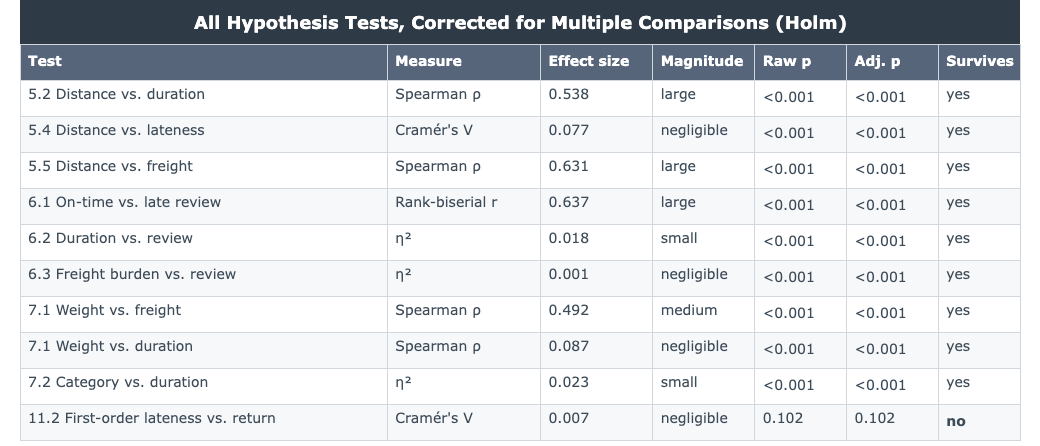

In [59]:
test_names = list(tests)
raw_p = [tests[name]["p_value"] for name in test_names]
still_significant, adjusted_p, _, _ = multipletests(raw_p, alpha=0.05, method="holm")

display_stylized_table(
    title="All Hypothesis Tests, Corrected for Multiple Comparisons (Holm)",
    headers=("Test", "Measure", "Effect size", "Magnitude", "Raw p", "Adj. p", "Survives"),
    rows=[
        (
            name,
            EFFECT_MEASURES.get(name, ""),
            f"{tests[name]['effect']:.3f}",
            tests[name]["effect_size"],
            "&lt;0.001" if raw_p[i] < 0.001 else f"{raw_p[i]:.3f}",
            "&lt;0.001" if adjusted_p[i] < 0.001 else f"{adjusted_p[i]:.3f}",
            "yes" if still_significant[i] else "<b>no</b>",
        )
        for i, name in enumerate(test_names)
    ],
)

Nine of the ten tests remain significant after adjustment; the exception is first-order lateness and returning (11.2). The effect sizes separate the results more usefully. Three relationships are large: distance with delivery duration, distance with freight, and on-time delivery with review score. Weight with freight is medium. The other significant results are small or negligible: distance with lateness, delivery duration with review score among on-time orders, freight burden with review score, weight with delivery duration, and product category with delivery duration. The effect sizes use different measures depending on the test, so the magnitude labels are more comparable than the numbers.

### 12.2 Key Takeaways and Next Steps

This analysis began without a fixed question and followed the marketplace from geography to delivery, satisfaction and repeat purchasing. The main findings are:

- **Sellers are concentrated and customers are spread out,** so the distance between them varies widely (Section 4).
- **Delivery time varies widely and follows distance.** The median delivery takes 10 days and 5% take 29 days or more. Distance has a large association with delivery time (ρ = 0.54), and the added time comes from carrier transit, not from the time before handoff (Section 5).
- **Olist’s delivery estimates are loose.** The median order arrives 12 days early, and the estimate is typically 13 days from the actual delivery date. Estimates stayed near three weeks while actual delivery times rose and fell (Sections 5 and 8).
- **Customers respond to whether the estimate is met.** Late orders average 2.27 stars against 4.29 for on-time orders, and the words that most distinguish positive from negative reviews concern whether and when the order arrived (Sections 6 and 10).
- **What is shipped matters less than how far it travels.** Weight and product category have small or negligible associations with delivery time, while sellers differ by several days in how quickly they hand orders to the carrier (Sections 7 and 9).
- **Repeat purchasing is rare.** Across the full study period, 3.05% of customers placed more than one order. Within 180 days of receiving their first order, 1.85% of customers whose order arrived on time order again, compared with 1.38% of those whose order arrived late. There is no clear association between first-order lateness and repeat purchasing within that window (Section 11).

Taken together, these findings point to delivery time as the outcome most worth predicting. It varies widely, it is related to information available when an order is placed (distance, seller, product and time of purchase), the existing estimates leave substantial room for improvement, and meeting the estimate is what customers’ ratings reflect.

The next notebook takes up that question: how accurately can delivery time be predicted at the time of purchase, and how would more accurate estimates trade off against the risk of late deliveries? Olist’s own estimate provides the point of comparison.